In [1]:
import sys
import os
from typing import NamedTuple
import math
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold


from utils import read_utils
from utils import plot_utils
from utils import train_utils
from utils import artificializer


sys.path.append(os.path.join(os.getcwd(), '../../'))
from models import bom
from models import hgm

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/ZimmerLab/MSc_Thesis/Workspace/hobe/worm-2025-fieseler/import/models/hgm.py'>

# Functions

In [4]:
class Lambdas(NamedTuple):
	loss_lambdas: tuple[float, float]
	reg_lambdas: tuple[float, float]
	cca_lambdas: tuple[float, float]

In [5]:
def separate_losses(file_ids, columns, models_spn_man_rec_res_pres):
	models_spn = [
		[
			pd.DataFrame(data=np.array(split[0])[None], columns=columns[i]) for split in models_spn_man_rec_res_pres[i]
		] for i in range(len(file_ids))
	]
	models_man = [
		[
			pd.DataFrame(data=np.array(split[1]), columns=[f'M{i}' for i in range(np.array(split[1]).shape[1])]) for split in models_spn_man_rec_res_pres[i]
		] for i in range(len(file_ids))
	]
	(models_rec,
	 models_res,
	 models_pres) = tuple(
		[
			[
				pd.DataFrame(data=np.array(split[m]), columns=columns[i]) for split in models_spn_man_rec_res_pres[i]
			] for i in range(len(file_ids))
		] for m in [2, 3, 4]
	)
	return models_spn, models_man, models_rec, models_res, models_pres

In [6]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

# read & prep

In [7]:
default_hyperparameters = {
	'dimensions': 1,
	'loss1_lambda': 0.67,
	'loss2_lambda': 1.0 - 0.67,
	'w1_reg_lambda': 0.0,	#1E-3,
	'w2_reg_lambda': 0.0,	#1E-5,
}

bom_reg_lamdas = {
	# 'w1_reg_lambda': default_hyperparameters['w1_reg_lambda'],
	'w1_reg_lambda': 1E-2,
}
hgm_reg_lamdas = {
	# 'w1_reg_lambda': default_hyperparameters['w1_reg_lambda'],
	# 'w2_reg_lambda': default_hyperparameters['w2_reg_lambda'],
	'w1_reg_lambda': 3E-3,
	'w2_reg_lambda': 1E-7,
}


selection_n_scores = ['VB02', 'DB01', 'DD01', 'AVBR', 'AVBL',	# paper
					  'RMDDR', 'SMDDR', 'SMDDL',				# C
					  'AVAR', 'AVAL',							# M
					  'ALA', 'AWBR']							# O

selection_n_traces = ['AVAR', 'ALA',
					  'SMDDL', 'RMDDR', 'SMDDR', 'VB02', 'DB01',
					  'SIADR', 'DD01']
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']



gcamp = True
read_ids_gcamp = list(range(0, 33+1))
# read_ids_gcamp = [0,   # minrevs
# 				  1,   # minswitch
# 				  7,   # maxswitch
# 				  11,  # median
# 				  12,  # maxrevs
# 				  17,  # mean
# 				  19,  # paper
# 				  21]  # clean
# read_ids_gcamp = [19]
plot_id_gcamp = 19


gfp = True
if gfp:
	read_ids_gfp = list(range(0, 7+1))
	# read_ids_gfp = [2, 4, 6]
	# read_ids_gfp = [2]
	plot_id_gfp = 2


artificial = True
if artificial:
	dims_generation = 2
	weights = (0.1, -0.25)

In [8]:
# read

path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
(file_ids_gcamp, filenames_gcamp,
 traces_gcamp,
 continuous_behaviors_gcamp,
 discrete_states_gcamp, eigenworms_gcamp,
 kymographs_gcamp) = read_utils.get_data(path, read_ids_gcamp)

# clear nan values
for i in range(len(file_ids_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)

	traces_gcamp[i] = traces_gcamp[i][mask]
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

# remove unused discrete state labels
discrete_states_gcamp = [ds[selection_bhl] for ds in discrete_states_gcamp]

# naive ID unknown neurons
for i in range(len(file_ids_gcamp)):
	traces_gcamp[i].columns = pd.Index([
		f'{file_ids_gcamp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gcamp[i].columns, traces_gcamp[i].columns == ''))
	])


if gfp:
	path_gfp = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gfp')
	(file_ids_gfp, filenames_gfp,
	 traces_gfp,
	 continuous_behaviors_gfp,
	 discrete_states_gfp, eigenworms_gfp,
	 kymographs_gfp) = read_utils.get_data(path_gfp, read_ids_gfp)

	# clear nan values
	for i in range(len(file_ids_gfp)):
		mask = eigenworms_gfp[i].notna().all(axis=1)

		traces_gfp[i] = traces_gfp[i][mask]
		#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
		eigenworms_gfp[i] = eigenworms_gfp[i][mask]
		discrete_states_gfp[i] = discrete_states_gfp[i][mask]

		#kymographs_gfp[i] = kymographs_gfp[i][mask]
		#filenames_gfp[i] = filenames_gfp[i][mask]

	# remove unused discrete state labels
	discrete_states_gfp = [ds[selection_bhl] for ds in discrete_states_gfp]

	# naive ID unknown neurons
	for i in range(len(file_ids_gfp)):
		traces_gfp[i].columns = pd.Index([
			f'{file_ids_gfp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gfp[i].columns, traces_gfp[i].columns == ''))
		])


# generate
if artificial:
	file_ids_art = list()
	filenames_art = list()

	discrete_states_art = list()
	eigenworms_art = list()

	modes_art = list()
	traces_reconstructed_art = list()
	traces_residual_art = list()
	traces_art = list()

	for i in range(len(file_ids_gcamp)):
		(filename_art,
		 neural_modes_art_,
		 traces_reconstructed_art_,
		 traces_residual_art_,
		 traces_art_,
		 params_art_,
		 params_cca_art_) = artificializer.artificialize(weights, hgm,
														 filenames_gcamp[i],
														 traces_gcamp[i].columns,
														 eigenworms_gcamp[i],
														 discrete_states_gcamp[i],
														 n_dimensions=dims_generation)
		filenames_art.append(filename_art)

		modes_art.append(neural_modes_art_)
		traces_reconstructed_art.append(traces_reconstructed_art_)
		traces_residual_art.append(traces_residual_art_)
		traces_art.append(traces_art_)

		file_ids_art.append(file_ids_gcamp[i])

		discrete_states_art.append(discrete_states_gcamp[i].copy())
		eigenworms_art.append(eigenworms_gcamp[i].copy())

In [9]:
selection_n_traces_gcamp = [label for label in selection_n_traces if label in traces_gcamp[file_ids_gcamp.index(plot_id_gcamp)].columns]
if gfp:
	selection_n_traces_gfp = [label for label in selection_n_traces if label in traces_gfp[file_ids_gfp.index(plot_id_gfp)].columns]

# read models

In [10]:
prefix = 'allfiles-d1-ll67'

In [11]:
if gcamp:
	bom_load_name_gcamp = os.path.join(prefix, f'bom_gcamp_w1-{bom_reg_lamdas['w1_reg_lambda']:.0E}')
	hgm_load_name_gcamp = os.path.join(prefix, f'hgm_gcamp_w1-{hgm_reg_lamdas['w1_reg_lambda']:.0E}_w2-{hgm_reg_lamdas['w2_reg_lambda']:.0E}')

if gfp:
	bom_load_name_gfp = os.path.join(prefix, f'bom_gfp_w1-{bom_reg_lamdas['w1_reg_lambda']:.0E}')
	hgm_load_name_gfp = os.path.join(prefix, f'hgm_gfp_w1-{hgm_reg_lamdas['w1_reg_lambda']:.0E}_w2-{hgm_reg_lamdas['w2_reg_lambda']:.0E}')

if artificial:
	bom_load_name_art = os.path.join(prefix, f'bom_art_w1-{bom_reg_lamdas['w1_reg_lambda']:.0E}')
	hgm_load_name_art = os.path.join(prefix, f'hgm_art_w1-{hgm_reg_lamdas['w1_reg_lambda']:.0E}_w2-{hgm_reg_lamdas['w2_reg_lambda']:.0E}')

In [12]:
if gcamp:
	boms_params_gcamp = train_utils.load_params(bom_load_name_gcamp, filenames_gcamp)

	boms_losses_gcamp_all = train_utils.load_losses(bom_load_name_gcamp, filenames_gcamp)
	boms_losses_train_gcamp = [losses[0] for losses in boms_losses_gcamp_all]
	boms_man_losses_train_gcamp = [losses[1] for losses in boms_losses_gcamp_all]
	boms_res_losses_train_gcamp = [losses[2] for losses in boms_losses_gcamp_all]
	boms_mpe_losses_train_gcamp = [losses[3] for losses in boms_losses_gcamp_all]
	boms_losses_gcamp = [losses[4] for losses in boms_losses_gcamp_all]
	boms_man_losses_gcamp = [losses[5] for losses in boms_losses_gcamp_all]
	boms_res_losses_gcamp = [losses[6] for losses in boms_losses_gcamp_all]
	boms_mpe_losses_gcamp = [losses[7] for losses in boms_losses_gcamp_all]

	hgms_params_gcamp = train_utils.load_params(hgm_load_name_gcamp, filenames_gcamp)

	hgms_losses_gcamp_all = train_utils.load_losses(hgm_load_name_gcamp, filenames_gcamp)
	hgms_losses_train_gcamp = [losses[0] for losses in hgms_losses_gcamp_all]
	hgms_man_losses_train_gcamp = [losses[1] for losses in hgms_losses_gcamp_all]
	hgms_res_losses_train_gcamp = [losses[2] for losses in hgms_losses_gcamp_all]
	hgms_mpe_losses_train_gcamp = [losses[3] for losses in hgms_losses_gcamp_all]
	hgms_losses_gcamp = [losses[4] for losses in hgms_losses_gcamp_all]
	hgms_man_losses_gcamp = [losses[5] for losses in hgms_losses_gcamp_all]
	hgms_res_losses_gcamp = [losses[6] for losses in hgms_losses_gcamp_all]
	hgms_mpe_losses_gcamp = [losses[7] for losses in hgms_losses_gcamp_all]


if gfp:
	boms_params_gfp = train_utils.load_params(bom_load_name_gfp, filenames_gfp)

	boms_losses_gfp_all = train_utils.load_losses(bom_load_name_gfp, filenames_gfp)
	boms_losses_train_gfp = [losses[0] for losses in boms_losses_gfp_all]
	boms_man_losses_train_gfp = [losses[1] for losses in boms_losses_gfp_all]
	boms_res_losses_train_gfp = [losses[2] for losses in boms_losses_gfp_all]
	boms_mpe_losses_train_gfp = [losses[3] for losses in boms_losses_gfp_all]
	boms_losses_gfp = [losses[4] for losses in boms_losses_gfp_all]
	boms_man_losses_gfp = [losses[5] for losses in boms_losses_gfp_all]
	boms_res_losses_gfp = [losses[6] for losses in boms_losses_gfp_all]
	boms_mpe_losses_gfp = [losses[7] for losses in boms_losses_gfp_all]

	hgms_params_gfp = train_utils.load_params(hgm_load_name_gfp, filenames_gfp)

	hgms_losses_gfp_all = train_utils.load_losses(hgm_load_name_gfp, filenames_gfp)
	hgms_losses_train_gfp = [losses[0] for losses in hgms_losses_gfp_all]
	hgms_man_losses_train_gfp = [losses[1] for losses in hgms_losses_gfp_all]
	hgms_res_losses_train_gfp = [losses[2] for losses in hgms_losses_gfp_all]
	hgms_mpe_losses_train_gfp = [losses[3] for losses in hgms_losses_gfp_all]
	hgms_losses_gfp = [losses[4] for losses in hgms_losses_gfp_all]
	hgms_man_losses_gfp = [losses[5] for losses in hgms_losses_gfp_all]
	hgms_res_losses_gfp = [losses[6] for losses in hgms_losses_gfp_all]
	hgms_mpe_losses_gfp = [losses[7] for losses in hgms_losses_gfp_all]


if artificial:
	boms_params_art = train_utils.load_params(bom_load_name_art, filenames_art)

	boms_losses_art_all = train_utils.load_losses(bom_load_name_art, filenames_art)
	boms_losses_train_art = [losses[0] for losses in boms_losses_art_all]
	boms_man_losses_train_art = [losses[1] for losses in boms_losses_art_all]
	boms_res_losses_train_art = [losses[2] for losses in boms_losses_art_all]
	boms_mpe_losses_train_art = [losses[3] for losses in boms_losses_art_all]
	boms_losses_art = [losses[4] for losses in boms_losses_art_all]
	boms_man_losses_art = [losses[5] for losses in boms_losses_art_all]
	boms_res_losses_art = [losses[6] for losses in boms_losses_art_all]
	boms_mpe_losses_art = [losses[7] for losses in boms_losses_art_all]

	hgms_params_art = train_utils.load_params(hgm_load_name_art, filenames_art)

	hgms_losses_art_all = train_utils.load_losses(hgm_load_name_art, filenames_art)
	hgms_losses_train_art = [losses[0] for losses in hgms_losses_art_all]
	hgms_man_losses_train_art = [losses[1] for losses in hgms_losses_art_all]
	hgms_res_losses_train_art = [losses[2] for losses in hgms_losses_art_all]
	hgms_mpe_losses_train_art = [losses[3] for losses in hgms_losses_art_all]
	hgms_losses_art = [losses[4] for losses in hgms_losses_art_all]
	hgms_man_losses_art = [losses[5] for losses in hgms_losses_art_all]
	hgms_res_losses_art = [losses[6] for losses in hgms_losses_art_all]
	hgms_mpe_losses_art = [losses[7] for losses in hgms_losses_art_all]

# artificial

### losses

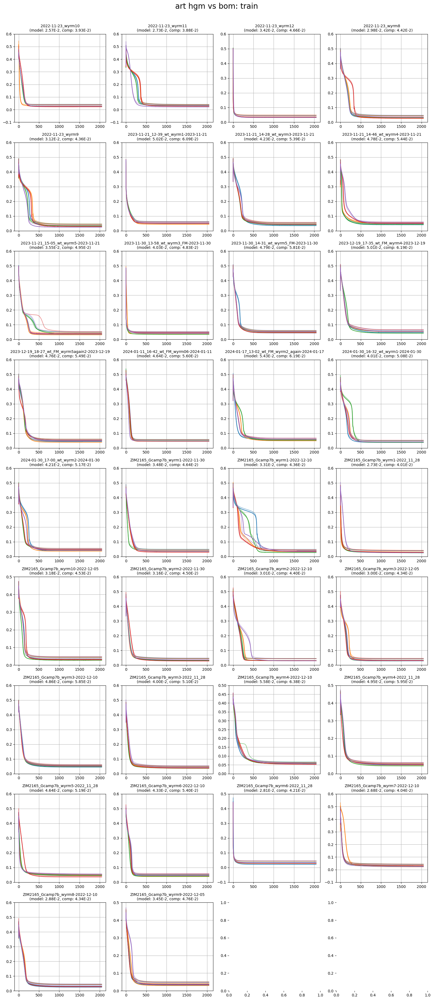

In [13]:
if artificial:
	plot_utils.plot_losses_splits('art hgm vs bom: train',
								  filenames_art,
								  hgms_losses_train_art, boms_losses_train_art,
								  ylimits=None)

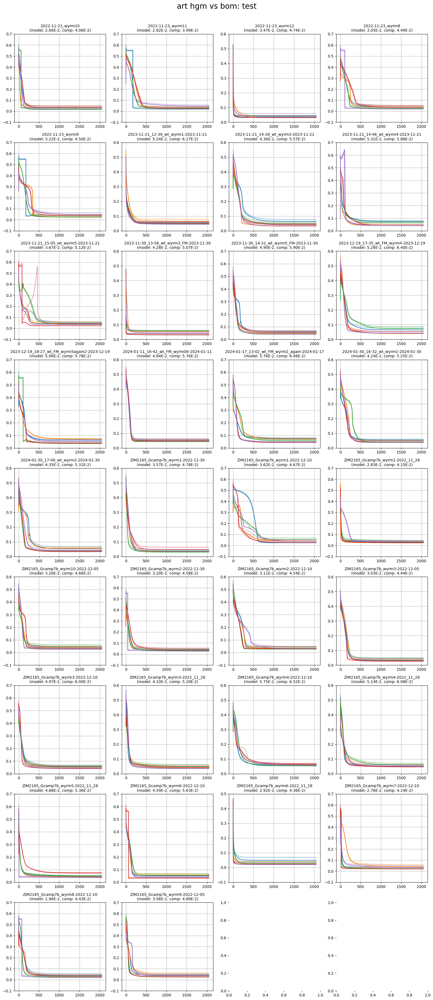

In [14]:
if artificial:
	plot_utils.plot_losses_splits('art hgm vs bom: test',
								  filenames_art,
								  hgms_losses_art, boms_losses_art,
								  ylimits=None)

### predict & score

In [15]:
if artificial:
	splits_art = [list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces_art[i].shape[0]), discrete_states_art[i][['REV']].values)) for i in range(len(file_ids_art))]

In [16]:
if artificial:
	boms_spn_man_rec_res_pres_art = [[
		bom.score_fn(params, traces_art[i].values[eval], eigenworms_art[i].values[eval]) for params, (train, eval) in zip(boms_params_art[i], splits_art[i])
	] for i in range(len(file_ids_art))]

	hgms_spn_man_rec_res_pres_art = [[
		hgm.score_fn(params, traces_art[i].values[eval], eigenworms_art[i].values[eval]) for params, (train, eval) in zip(hgms_params_art[i], splits_art[i])
	] for i in range(len(file_ids_art))]

	(boms_spn_art,
	 boms_man_art,
	 boms_rec_art,
	 boms_res_art,
	 boms_pres_art) = separate_losses(file_ids_art, [trace.columns for trace in traces_art], boms_spn_man_rec_res_pres_art)

	(hgms_spn_art,
	 hgms_man_art,
	 hgms_rec_art,
	 hgms_res_art,
	 hgms_pres_art) = separate_losses(file_ids_art, [trace.columns for trace in traces_art], hgms_spn_man_rec_res_pres_art)

### performance

In [17]:
if artificial:
	neuron_scores_art = assemble(boms_spn_art, hgms_spn_art)

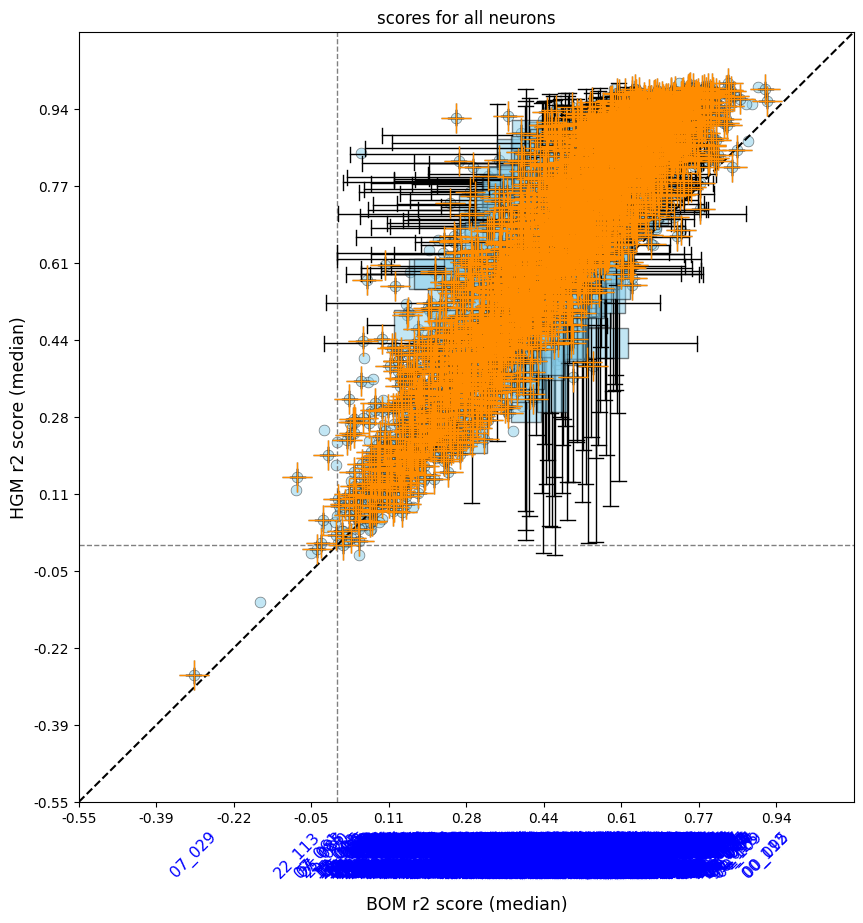

In [18]:
if artificial:
	plot_utils.plot_performance_plot(neuron_scores_art, None,
									 title='scores for all neurons', limits=(-0.55, 1.1, -0.55, 1.1))

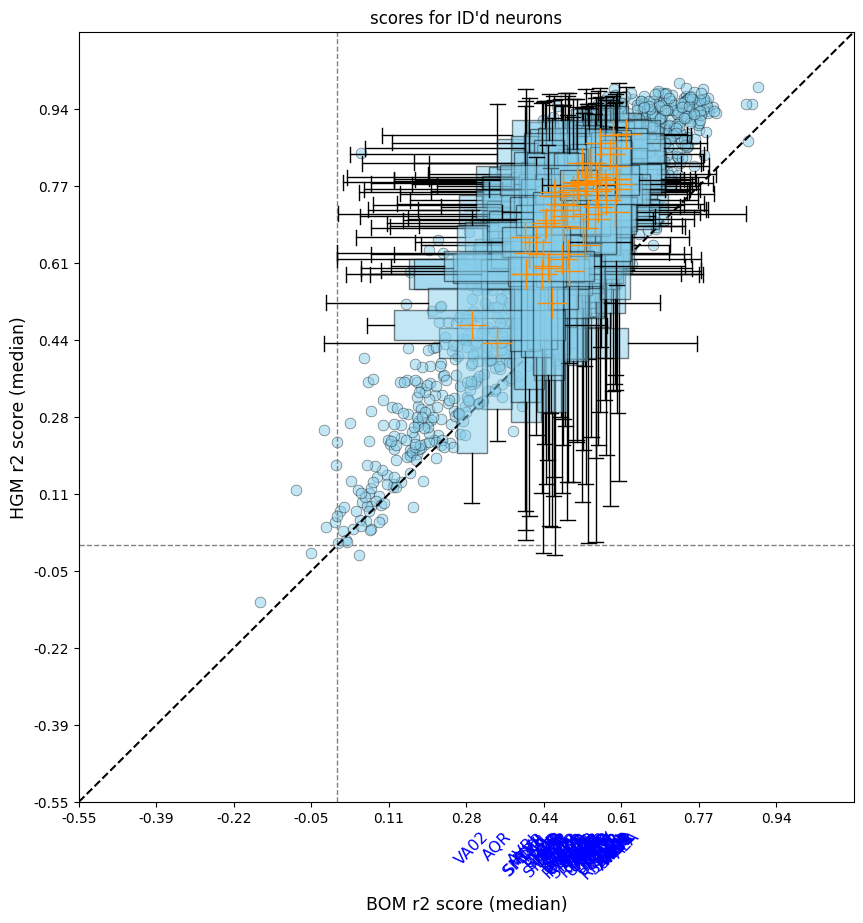

In [19]:
if artificial:
	plot_utils.plot_performance_plot({key: neuron_scores_art[key] for key in neuron_scores_art.keys() if not key[0].isdigit()}, None,
									 title='scores for ID\'d neurons', limits=(-0.55, 1.1, -0.55, 1.1))

In [20]:
# if artificial:
# 	plot_utils.plot_performance_plot({key: neuron_scores_art[key] for key in selection_n_scores if key in neuron_scores_art.keys()}, None,
# 								 	title='scores for handpicked neurons', limits=(-0.55, 1.1, -0.55, 1.1))

### traces

In [21]:
if artificial:
	boms_spn_man_rec_res_pres_art = [[
		bom.score_fn(params, traces_art[i].values, eigenworms_art[i].values) for params in boms_params_art[i]
	] for i in range(len(file_ids_art))]

	hgms_spn_man_rec_res_pres_art = [[
		hgm.score_fn(params, traces_art[i].values, eigenworms_art[i].values) for params in hgms_params_art[i]
	] for i in range(len(file_ids_art))]

	(boms_spn_art_full,
	 boms_man_art_full,
	 boms_rec_art_full,
	 boms_res_art_full,
	 boms_pres_art_full) = separate_losses(file_ids_art, [trace.columns for trace in traces_art], boms_spn_man_rec_res_pres_art)

	(hgms_spn_art_full,
	 hgms_man_art_full,
	 hgms_rec_art_full,
	 hgms_res_art_full,
	 hgms_pres_art_full) = separate_losses(file_ids_art, [trace.columns for trace in traces_art], hgms_spn_man_rec_res_pres_art)

In [22]:
if artificial:
	_, _, traces_art_cca_rec, _, _, _, _, _ = train_utils.get_manifolds_cca(traces_art, discrete_states_art, n_cv=default_hyperparameters['dimensions'], n_pc=0)
	traces_art_cca_res = [pd.DataFrame(data=trace_art.values - trace_art_cca_rec.values, columns=trace_art.columns) for trace_art, trace_art_cca_rec in zip(traces_art, traces_art_cca_rec)]

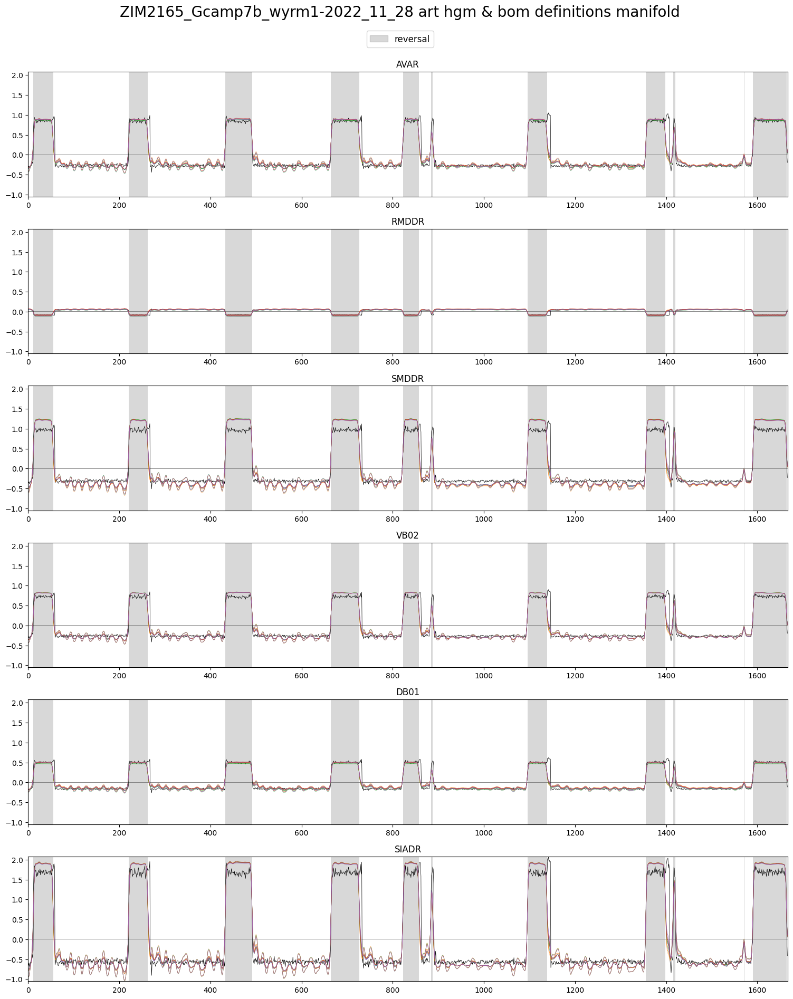

In [23]:
if artificial:
	splits = 5
	plot_utils.plot_traces_x_splits(
		f'{filenames_art[file_ids_art.index(plot_id_gcamp)]} art hgm & bom definitions manifold',
		discrete_states_art[file_ids_art.index(plot_id_gcamp)][['REV']],
		traces_art_cca_rec[file_ids_art.index(plot_id_gcamp)][selection_n_traces_gcamp],
		[hgms_rec_art_full[file_ids_art.index(plot_id_gcamp)][i][selection_n_traces_gcamp] for i in range(splits)],
		[boms_rec_art_full[file_ids_art.index(plot_id_gcamp)][i][selection_n_traces_gcamp] for i in range(splits)],
		plot_first=True, plots_per_row=1, ylimits=None,
		save_name='ART_MAN')

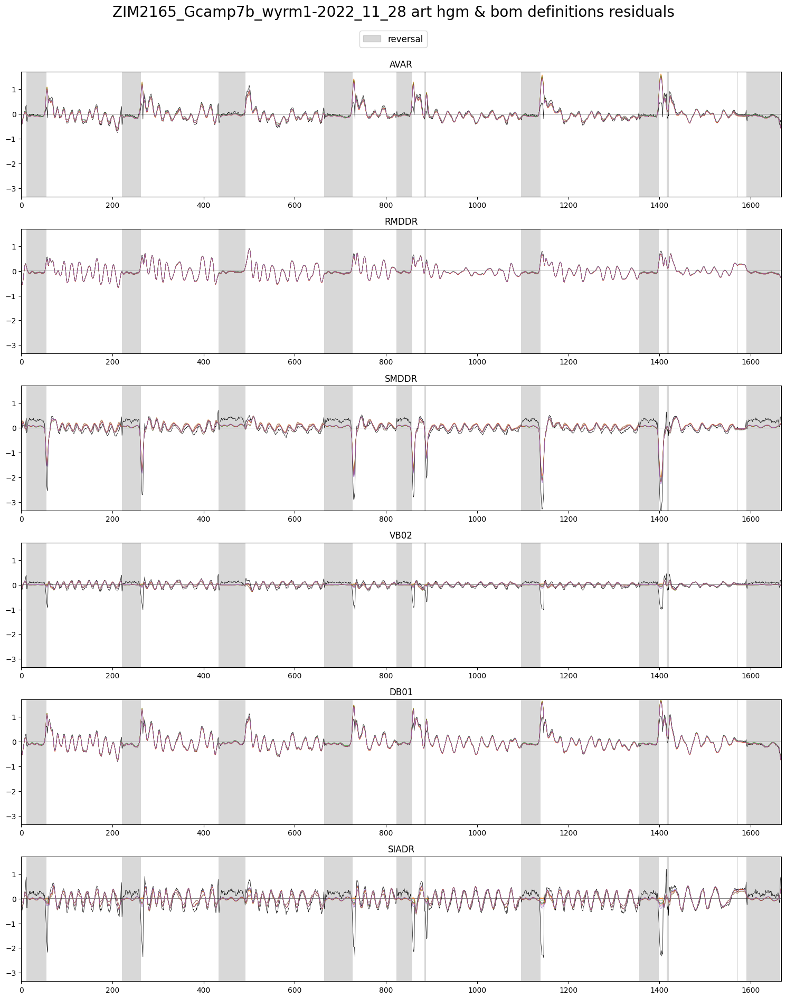

In [24]:
if artificial:
	splits = 5
	plot_utils.plot_traces_x_splits(
		f'{filenames_art[file_ids_art.index(plot_id_gcamp)]} art hgm & bom definitions residuals',
		discrete_states_art[file_ids_art.index(plot_id_gcamp)][['REV']],
		traces_art_cca_res[file_ids_art.index(plot_id_gcamp)][selection_n_traces_gcamp],
		[hgms_res_art_full[file_ids_art.index(plot_id_gcamp)][i][selection_n_traces_gcamp] for i in range(splits)],
		[boms_res_art_full[file_ids_art.index(plot_id_gcamp)][i][selection_n_traces_gcamp] for i in range(splits)],
		plot_first=True, plots_per_row=1, ylimits=None,
		save_name='ART_RES')

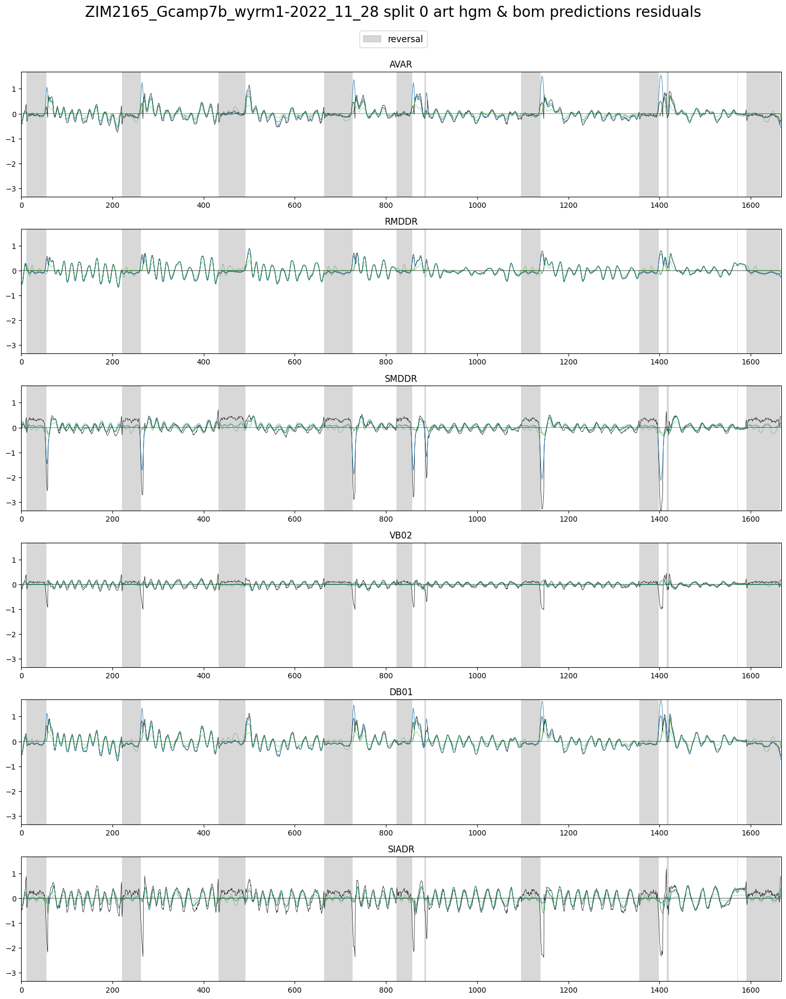

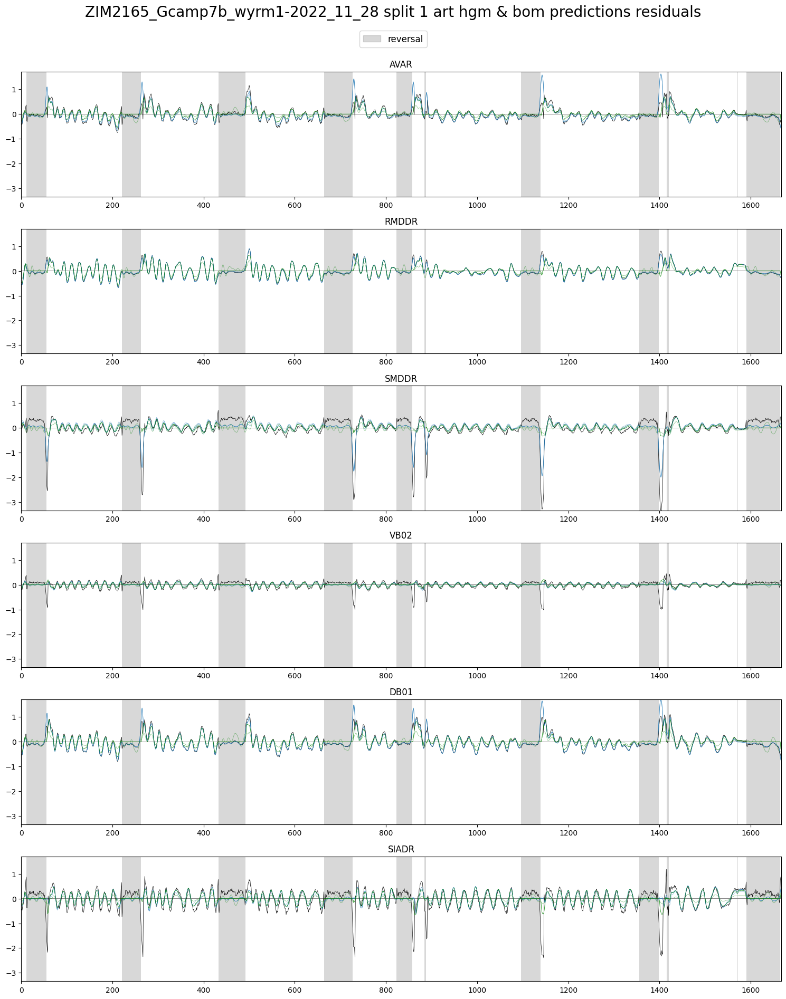

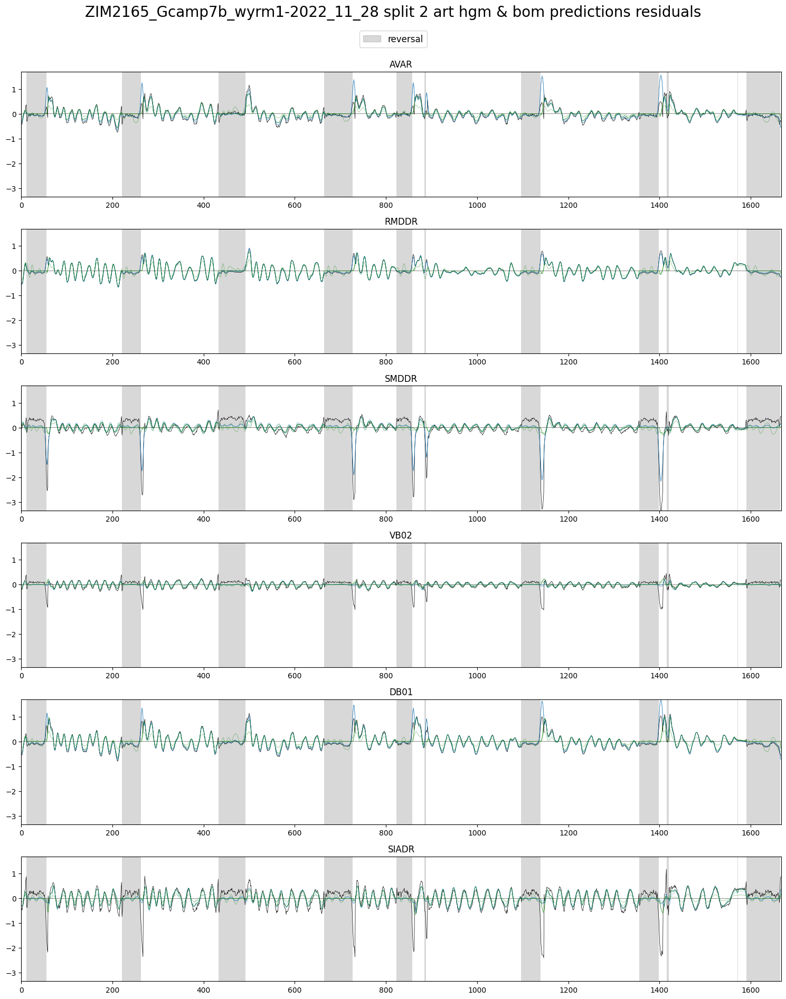

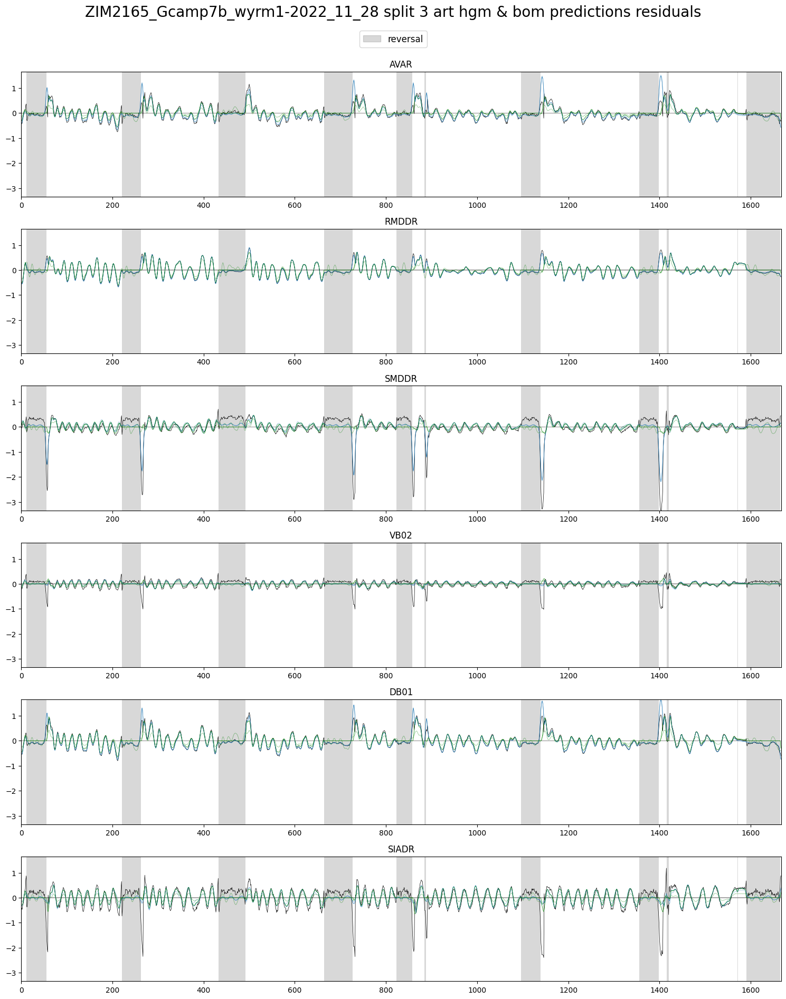

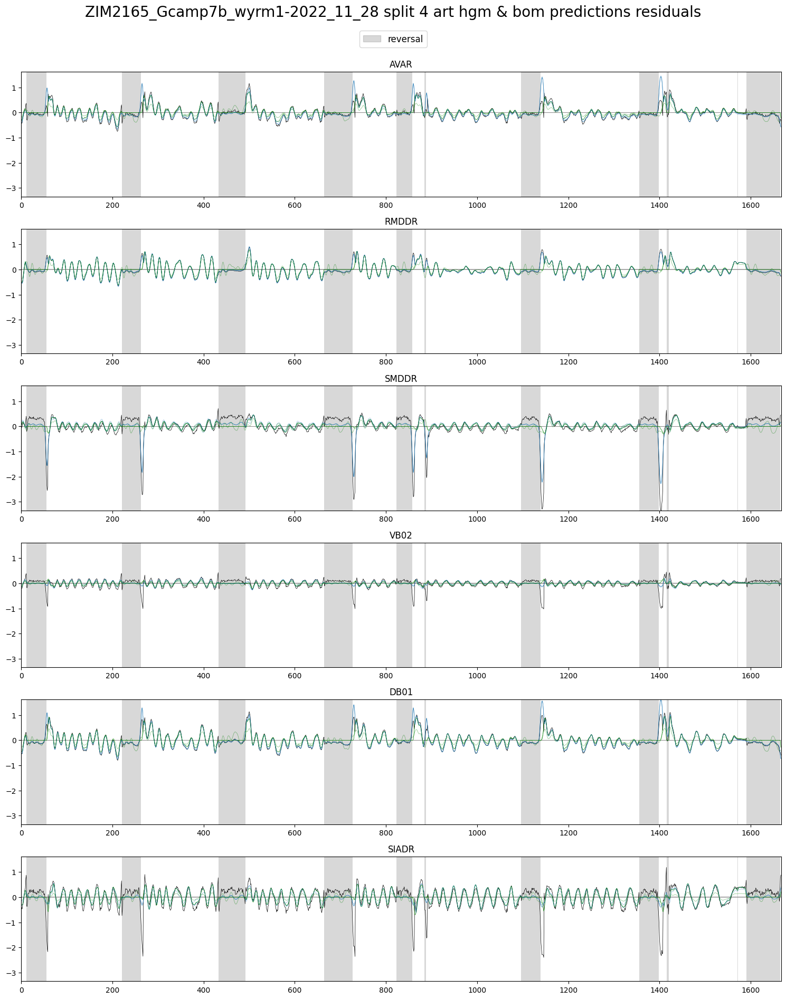

In [25]:
if artificial:
	for i in range(5):
		plot_utils.plot_traces_comparisons(
			f'{filenames_art[file_ids_art.index(plot_id_gcamp)]} split {i} art hgm & bom predictions residuals',
			discrete_states_art[file_ids_art.index(plot_id_gcamp)][['REV']],
			traces_art_cca_res[file_ids_art.index(plot_id_gcamp)][selection_n_traces_gcamp],
			[hgms_res_art_full[file_ids_art.index(plot_id_gcamp)][i][selection_n_traces_gcamp],
			 hgms_pres_art_full[file_ids_art.index(plot_id_gcamp)][i][selection_n_traces_gcamp]],
			[boms_res_art_full[file_ids_art.index(plot_id_gcamp)][i][selection_n_traces_gcamp],
			 boms_pres_art_full[file_ids_art.index(plot_id_gcamp)][i][selection_n_traces_gcamp]],
			plot_first=True, plots_per_row=1, ylimits=None,
			save_name=f'ART_PRES_S{i}')

 # gcamp

### losses

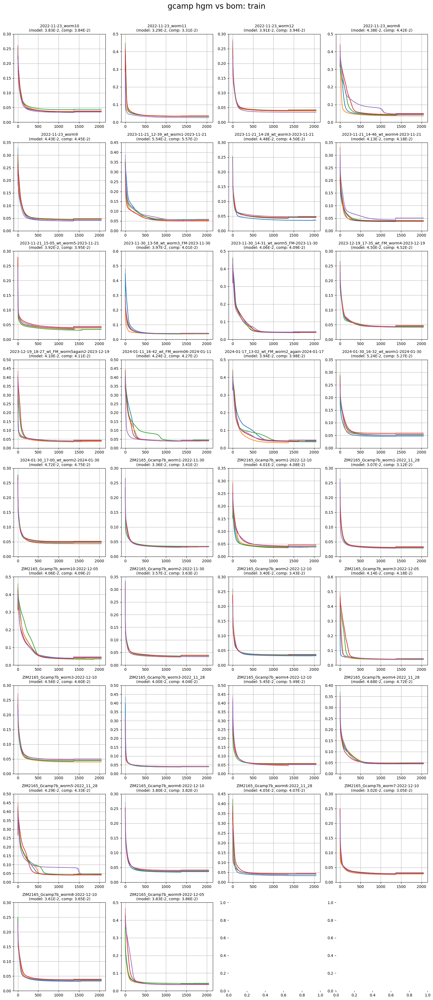

In [26]:
if gcamp:
	plot_utils.plot_losses_splits('gcamp hgm vs bom: train',
								  filenames_gcamp,
								  hgms_losses_train_gcamp, boms_losses_train_gcamp,
								  ylimits=None)

In [27]:
# if gcamp:
# 	plot_utils.plot_losses_splits('gcamp hgm vs bom: man train',
# 								  filenames_gcamp,
# 								  hgms_man_losses_train_gcamp, boms_man_losses_train_gcamp,
# 								  ylimits=None)

In [28]:
# if gcamp:
# 	plot_utils.plot_losses_splits('gcamp hgm vs bom: res train',
# 								  filenames_gcamp,
# 								  hgms_res_losses_train_gcamp, boms_res_losses_train_gcamp,
# 								  ylimits=None)

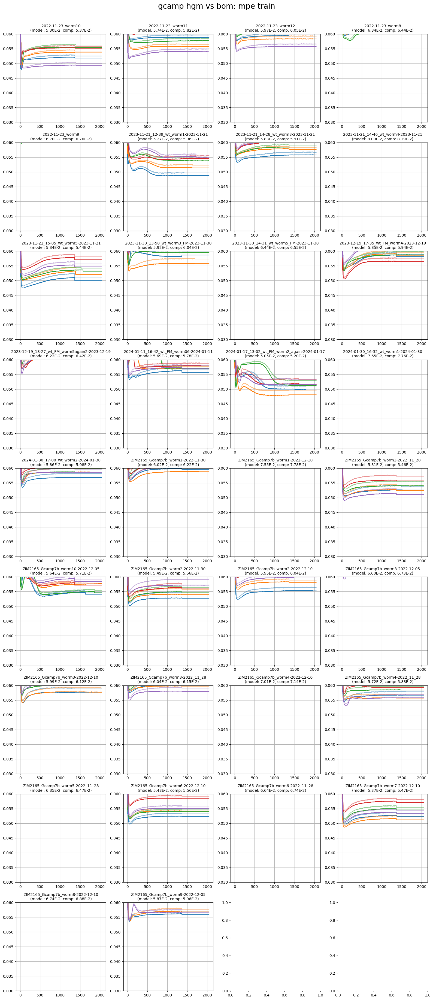

In [29]:
if gcamp:
	plot_utils.plot_losses_splits('gcamp hgm vs bom: mpe train',
								  filenames_gcamp,
								  hgms_mpe_losses_train_gcamp, boms_mpe_losses_train_gcamp,
								  ylimits=(0.03, 0.06))

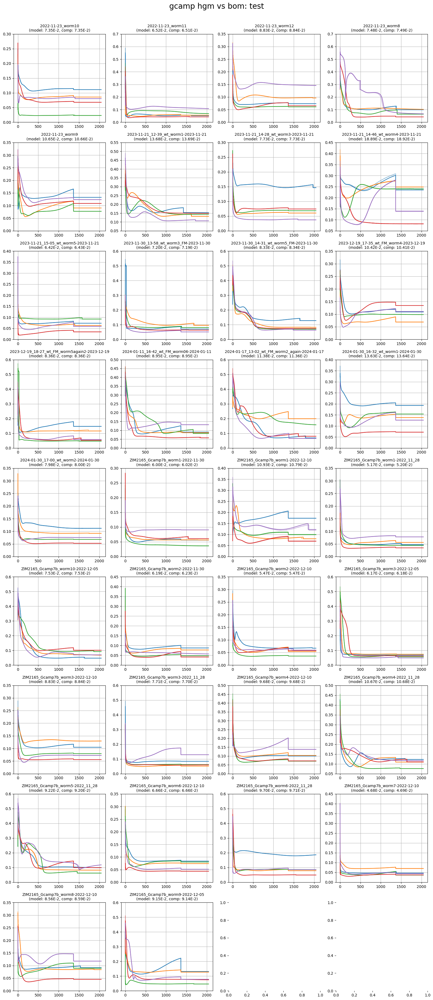

In [30]:
if gcamp:
	plot_utils.plot_losses_splits('gcamp hgm vs bom: test',
								  filenames_gcamp,
								  hgms_losses_gcamp, boms_losses_gcamp,
								  ylimits=None)

In [31]:
# if gcamp:
# 	plot_utils.plot_losses_splits('gcamp hgm vs bom: man test',
# 								  filenames_gcamp,
# 								  hgms_man_losses_gcamp, boms_man_losses_gcamp,
# 								  ylimits=None)

In [32]:
# if gcamp:
# 	plot_utils.plot_losses_splits('gcamp hgm vs bom: res test',
# 								  filenames_gcamp,
# 								  hgms_res_losses_gcamp, boms_res_losses_gcamp,
# 								  ylimits=None)

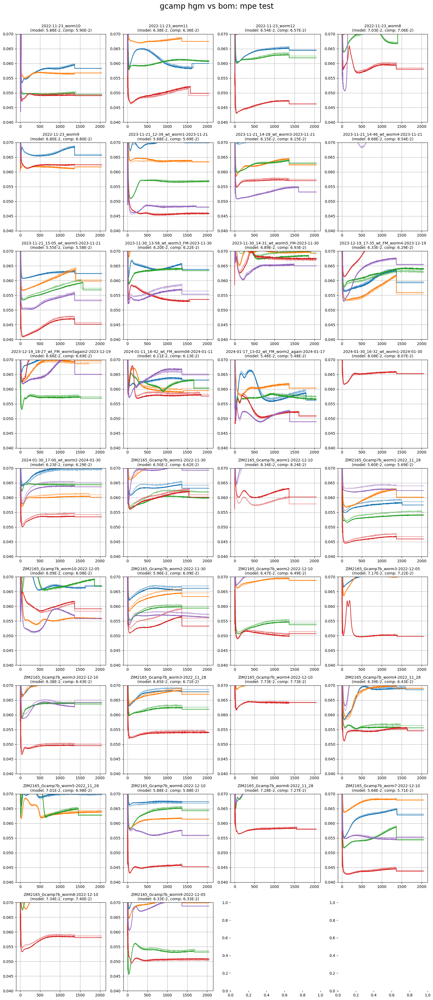

In [33]:
if gcamp:
	plot_utils.plot_losses_splits('gcamp hgm vs bom: mpe test',
								  filenames_gcamp,
								  hgms_mpe_losses_gcamp, boms_mpe_losses_gcamp,
								  ylimits=(0.04, 0.07))

### predict & score

In [34]:
if gcamp:
	splits_gcamp = [list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces_gcamp[i].shape[0]), discrete_states_gcamp[i][['REV']].values)) for i in range(len(file_ids_gcamp))]

In [35]:
if gcamp:
	boms_spn_man_rec_res_pres_gcamp = [[
		bom.score_fn(params, traces_gcamp[i].values[eval], eigenworms_gcamp[i].values[eval]) for params, (train, eval) in zip(boms_params_gcamp[i], splits_gcamp[i])
	] for i in range(len(file_ids_gcamp))]

	hgms_spn_man_rec_res_pres_gcamp = [[
		hgm.score_fn(params, traces_gcamp[i].values[eval], eigenworms_gcamp[i].values[eval]) for params, (train, eval) in zip(hgms_params_gcamp[i], splits_gcamp[i])
	] for i in range(len(file_ids_gcamp))]

	(boms_spn_gcamp,
	 boms_man_gcamp,
	 boms_rec_gcamp,
	 boms_res_gcamp,
	 boms_pres_gcamp) = separate_losses(file_ids_gcamp, [trace.columns for trace in traces_gcamp], boms_spn_man_rec_res_pres_gcamp)

	(hgms_spn_gcamp,
	 hgms_man_gcamp,
	 hgms_rec_gcamp,
	 hgms_res_gcamp,
	 hgms_pres_gcamp) = separate_losses(file_ids_gcamp, [trace.columns for trace in traces_gcamp], hgms_spn_man_rec_res_pres_gcamp)

### performance

In [36]:
if gcamp:
	neuron_scores_gcamp = assemble(boms_spn_gcamp, hgms_spn_gcamp)

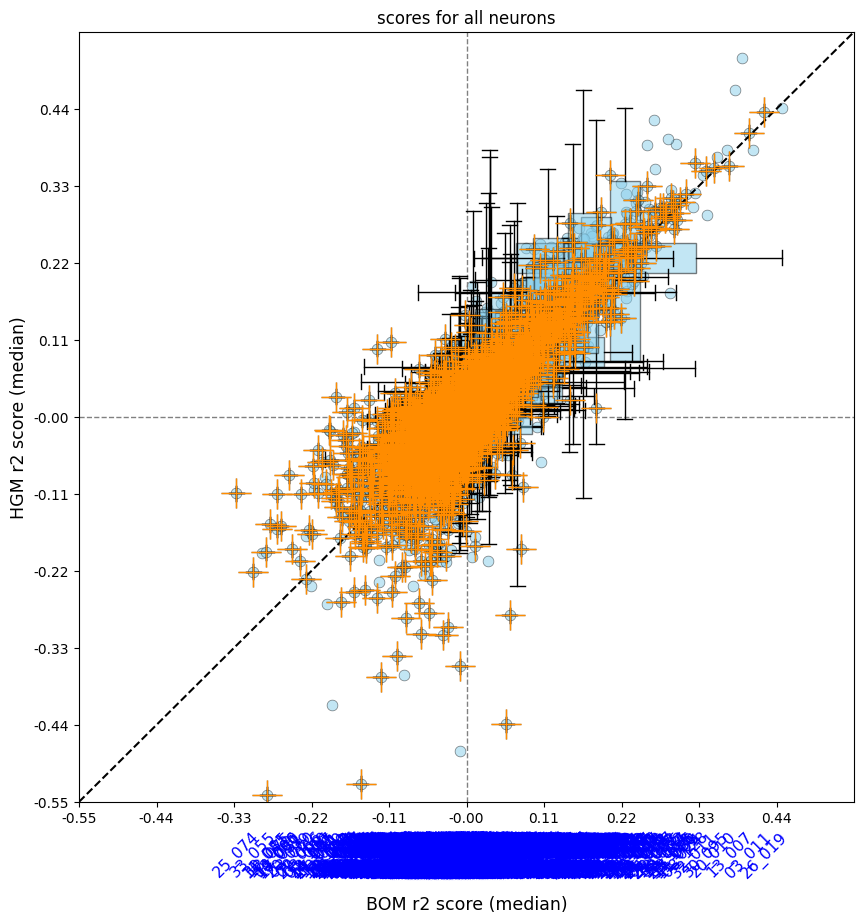

In [37]:
if gcamp:
	plot_utils.plot_performance_plot(neuron_scores_gcamp, None,
									 title='scores for all neurons', limits=(-0.55, 0.55, -0.55, 0.55))

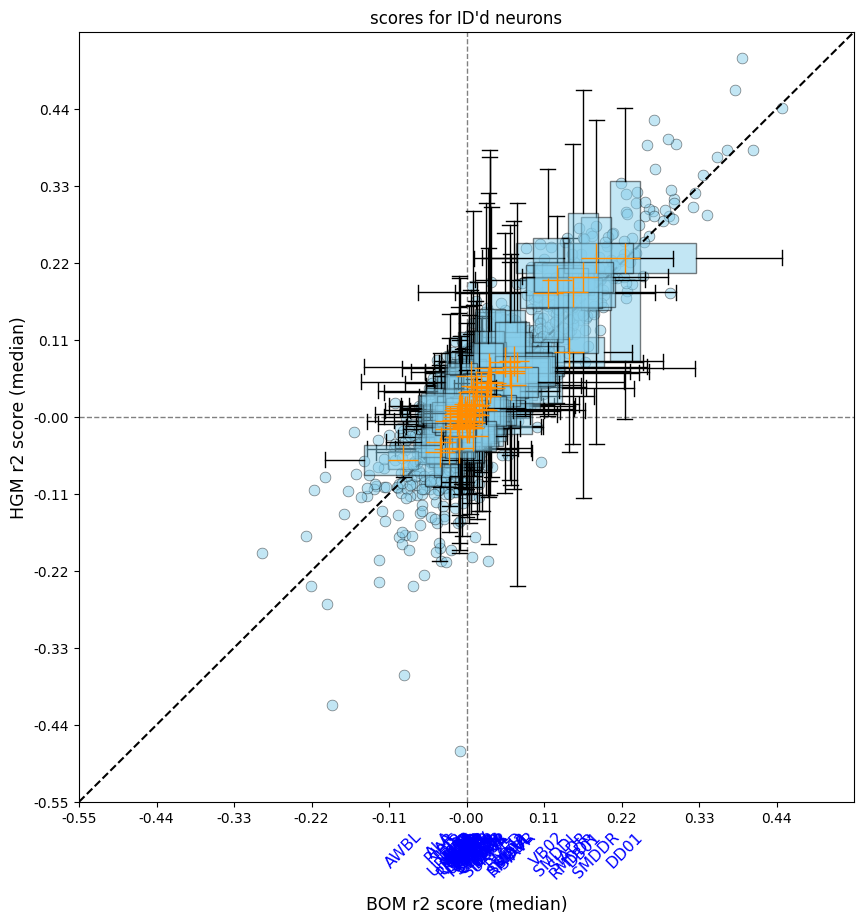

In [38]:
if gcamp:
	plot_utils.plot_performance_plot({key: neuron_scores_gcamp[key] for key in neuron_scores_gcamp.keys() if not key[0].isdigit()}, None,
								 	title='scores for ID\'d neurons', limits=(-0.55, 0.55, -0.55, 0.55))

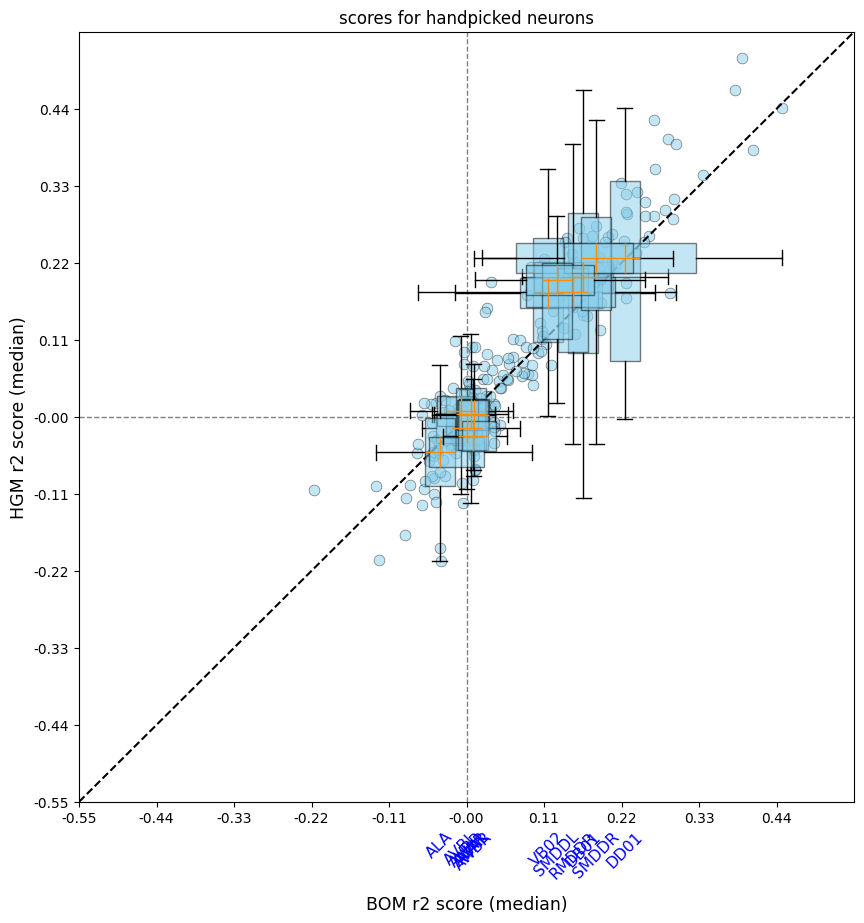

In [39]:
if gcamp:
	plot_utils.plot_performance_plot({key: neuron_scores_gcamp[key] for key in selection_n_scores if key in neuron_scores_gcamp.keys()}, None,
								 	title='scores for handpicked neurons', limits=(-0.55, 0.55, -0.55, 0.55))

### traces

In [40]:
if gcamp:
	boms_spn_man_rec_res_pres_gcamp = [[
		bom.score_fn(params, traces_gcamp[i].values, eigenworms_gcamp[i].values) for params in boms_params_gcamp[i]
	] for i in range(len(file_ids_gcamp))]

	hgms_spn_man_rec_res_pres_gcamp = [[
		hgm.score_fn(params, traces_gcamp[i].values, eigenworms_gcamp[i].values) for params in hgms_params_gcamp[i]
	] for i in range(len(file_ids_gcamp))]

	(boms_spn_gcamp_full,
	 boms_man_gcamp_full,
	 boms_rec_gcamp_full,
	 boms_res_gcamp_full,
	 boms_pres_gcamp_full) = separate_losses(file_ids_gcamp, [trace.columns for trace in traces_gcamp], boms_spn_man_rec_res_pres_gcamp)

	(hgms_spn_gcamp_full,
	 hgms_man_gcamp_full,
	 hgms_rec_gcamp_full,
	 hgms_res_gcamp_full,
	 hgms_pres_gcamp_full) = separate_losses(file_ids_gcamp, [trace.columns for trace in traces_gcamp], hgms_spn_man_rec_res_pres_gcamp)

In [41]:
# if gfp:
# 	neuron_imprsig_gcamp = {key: np.mean(neuron_scores_gcamp[key][1] - neuron_scores_gcamp[key][0]) for key in selection_n_hgmssig if key in neuron_scores_gcamp.keys()}
# 	selection_n_imprsig = [key for _, key in reversed(sorted(zip(neuron_imprsig_gcamp.values(), neuron_imprsig_gcamp.keys())))]

In [42]:
if gcamp:
	_, _, traces_gcamp_cca_rec, _, _, _, _, _ = train_utils.get_manifolds_cca(traces_gcamp, discrete_states_gcamp, n_cv=default_hyperparameters['dimensions'], n_pc=0)
	traces_gcamp_cca_res = [pd.DataFrame(data=trace_gcamp.values - trace_gcamp_cca_rec.values, columns=trace_gcamp.columns) for trace_gcamp, trace_gcamp_cca_rec in zip(traces_gcamp, traces_gcamp_cca_rec)]

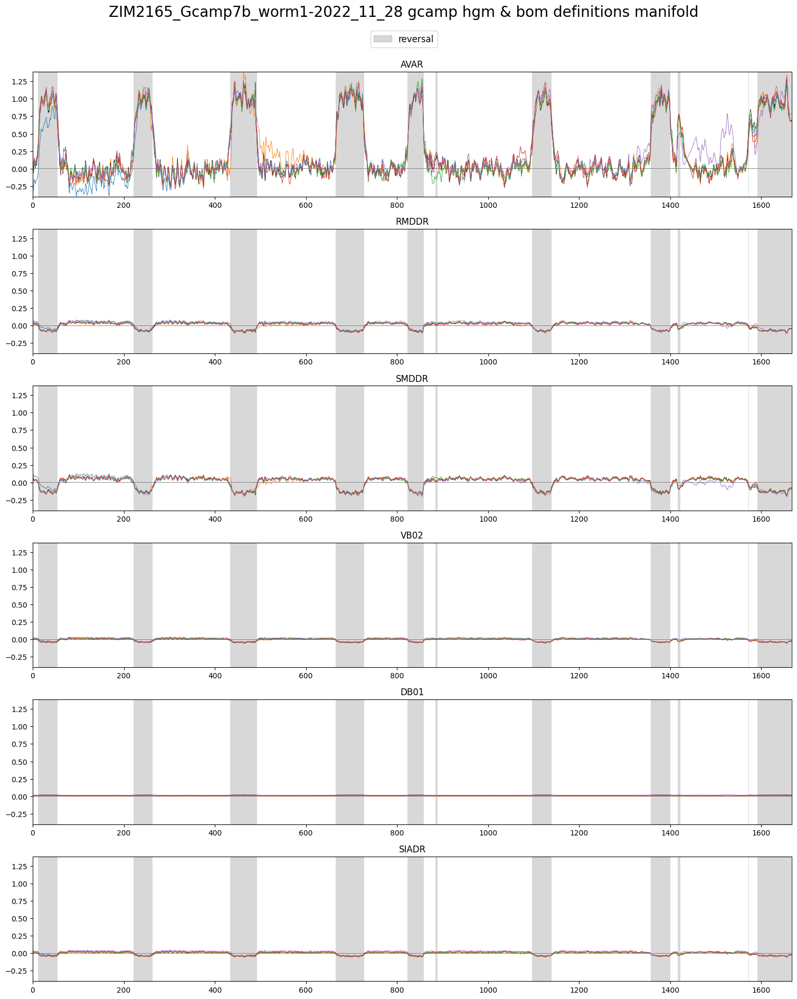

In [43]:
if gcamp:
	splits = 5
	plot_utils.plot_traces_x_splits(
		f'{filenames_gcamp[file_ids_gcamp.index(plot_id_gcamp)]} gcamp hgm & bom definitions manifold',
		discrete_states_gcamp[file_ids_gcamp.index(plot_id_gcamp)][['REV']],
		traces_gcamp_cca_rec[file_ids_gcamp.index(plot_id_gcamp)][selection_n_traces_gcamp],
		[hgms_rec_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][selection_n_traces_gcamp] for i in range(splits)],
		[boms_rec_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][selection_n_traces_gcamp] for i in range(splits)],
		plot_first=True, plots_per_row=1, ylimits=None,
		save_name='GCAMP_MAN')

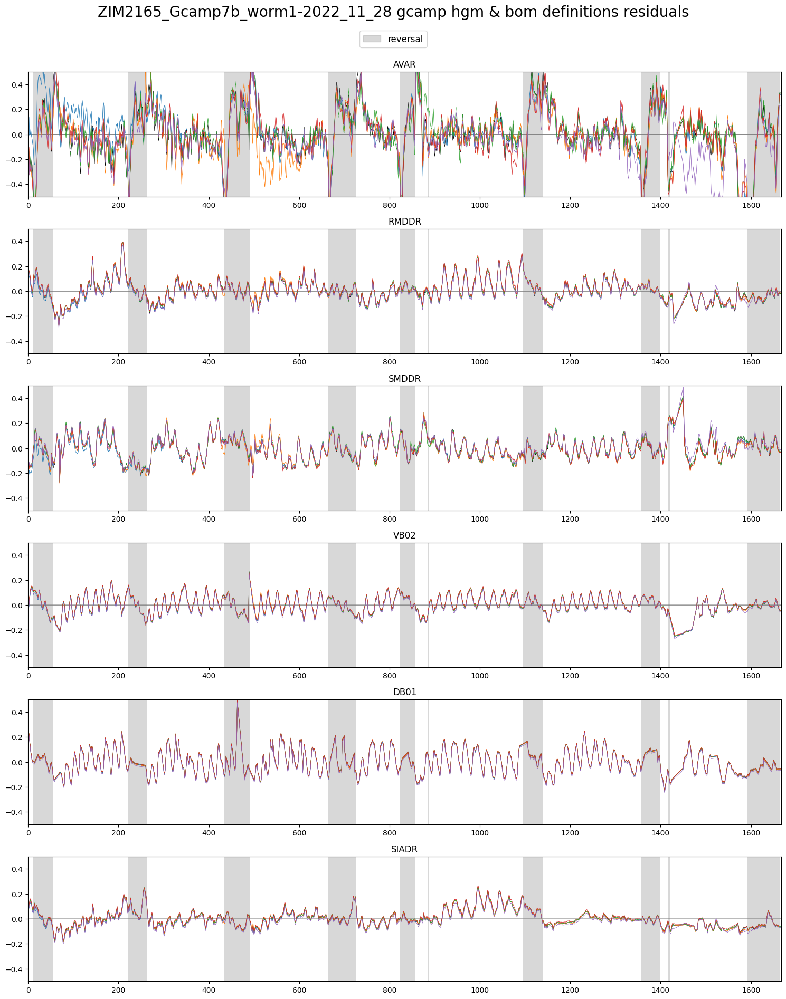

In [44]:
if gcamp:
	splits = 5
	plot_utils.plot_traces_x_splits(
		f'{filenames_gcamp[file_ids_gcamp.index(plot_id_gcamp)]} gcamp hgm & bom definitions residuals',
		discrete_states_gcamp[file_ids_gcamp.index(plot_id_gcamp)][['REV']],
		traces_gcamp_cca_res[file_ids_gcamp.index(plot_id_gcamp)][selection_n_traces_gcamp],
		[hgms_res_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][selection_n_traces_gcamp] for i in range(splits)],
		[boms_res_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][selection_n_traces_gcamp] for i in range(splits)],
		plot_first=True, plots_per_row=1, ylimits=(-0.5, 0.5),
		save_name='GCAMP_RES')

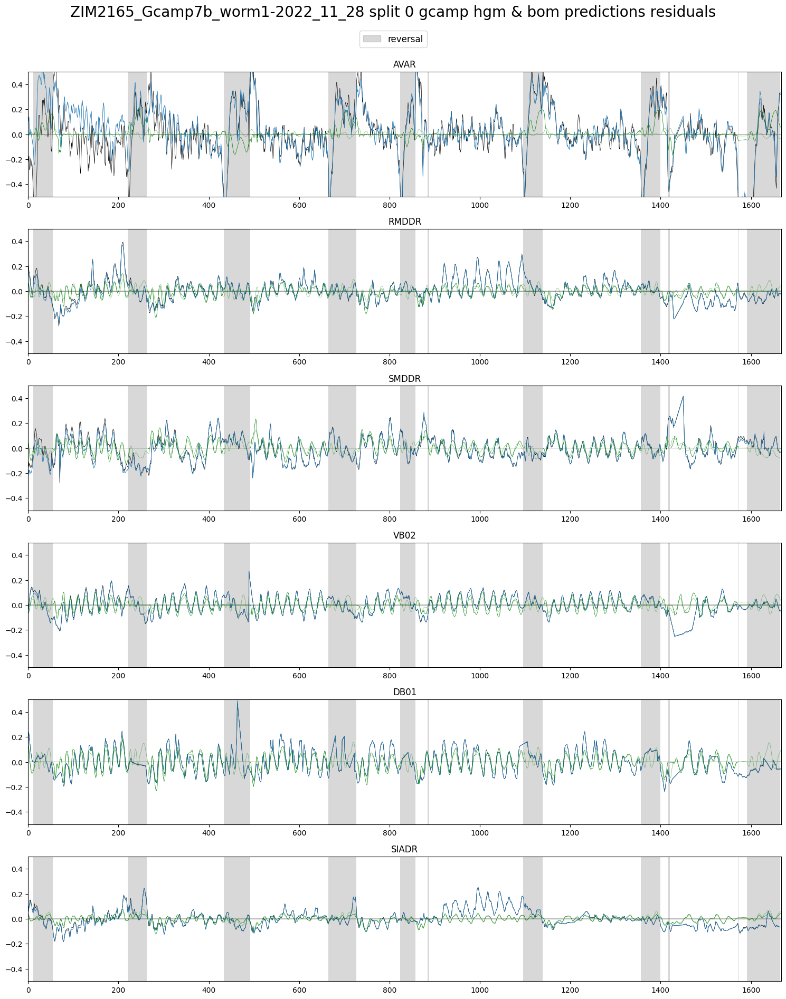

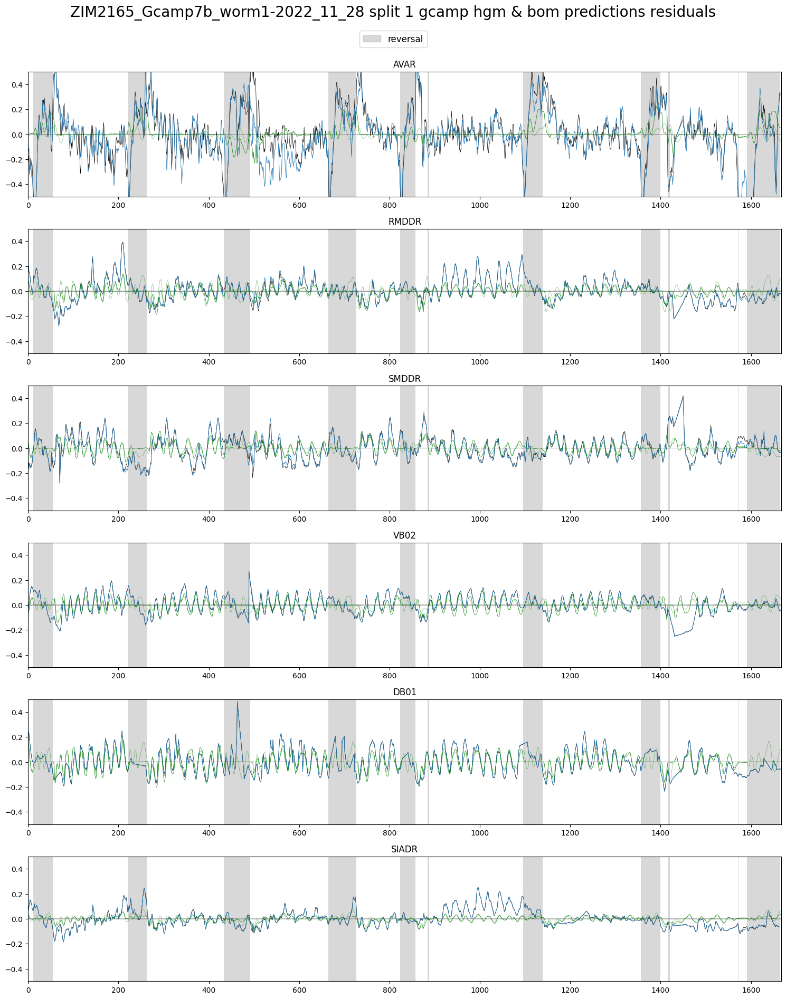

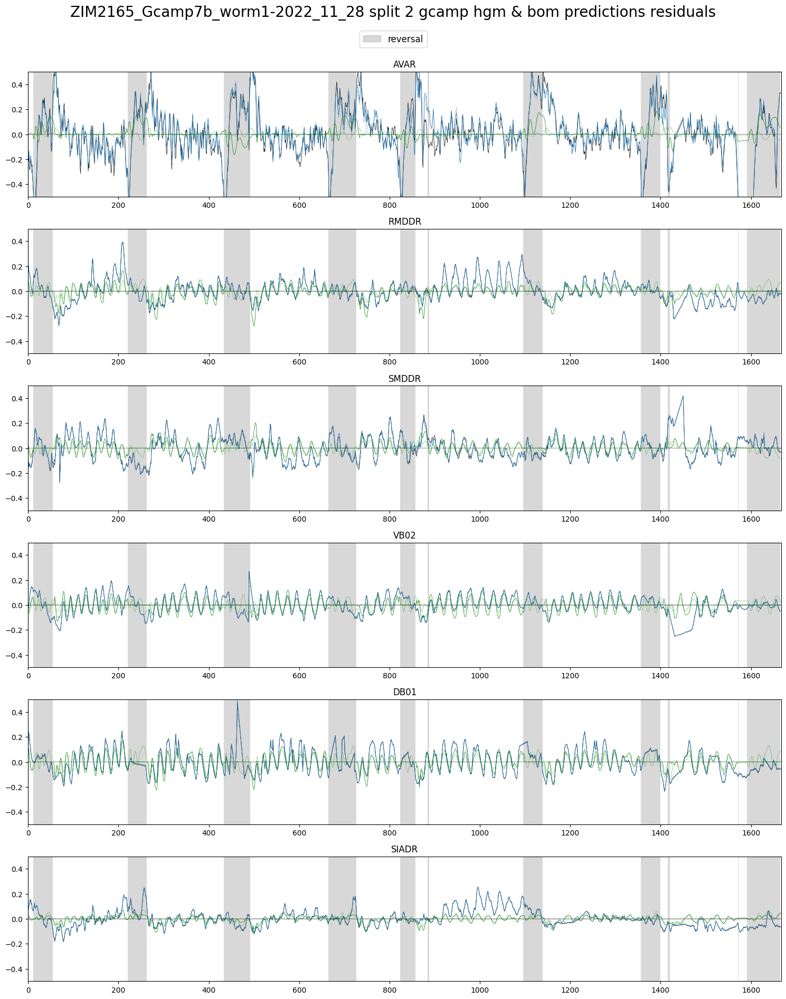

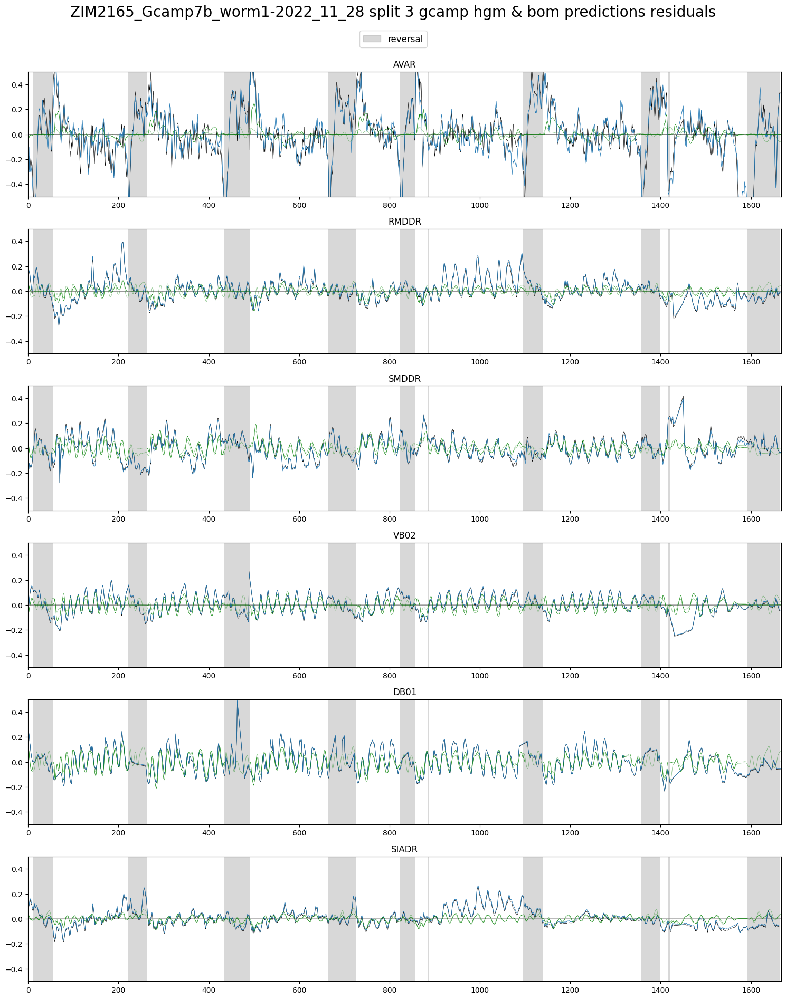

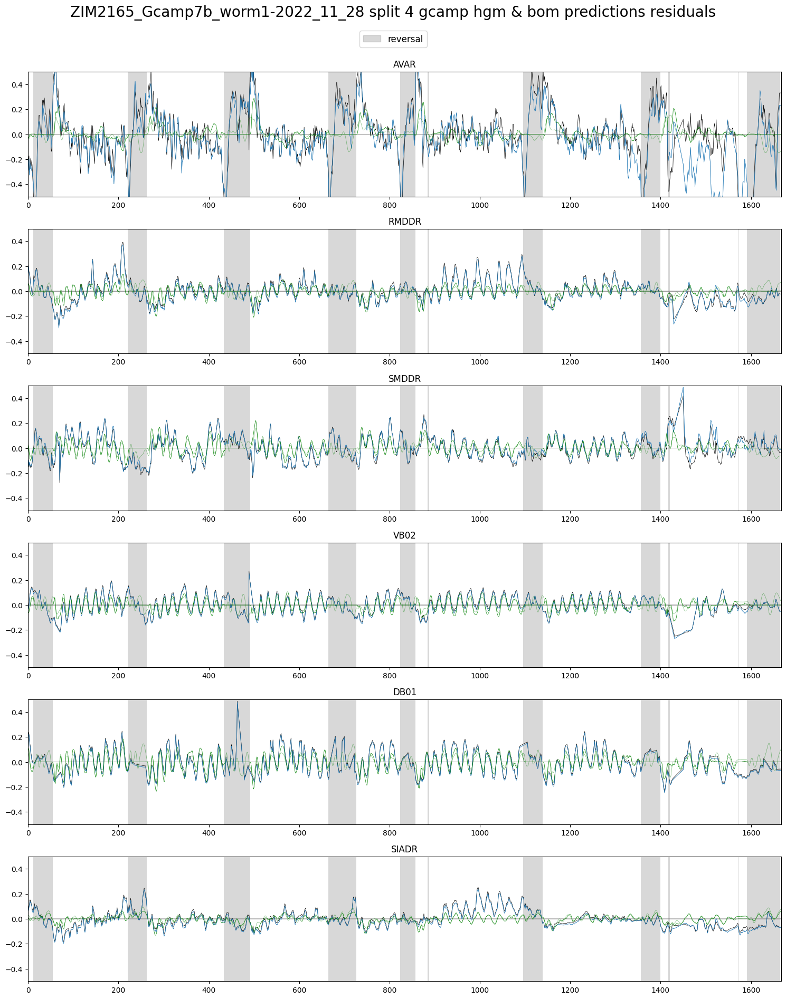

In [45]:
if gcamp:
	for i in range(5):
		plot_utils.plot_traces_comparisons(
			f'{filenames_gcamp[file_ids_gcamp.index(plot_id_gcamp)]} split {i} gcamp hgm & bom predictions residuals',
			discrete_states_gcamp[file_ids_gcamp.index(plot_id_gcamp)][['REV']],
			traces_gcamp_cca_res[file_ids_gcamp.index(plot_id_gcamp)][selection_n_traces_gcamp],
			[hgms_res_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][selection_n_traces_gcamp],
			 hgms_pres_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][selection_n_traces_gcamp]],
			[boms_res_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][selection_n_traces_gcamp],
			 boms_pres_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][selection_n_traces_gcamp]],
			plot_first=True, plots_per_row=1, ylimits=(-0.5, 0.5),
			save_name=f'GCAMP_PRES_S{i}')

# gfp

### predict & score

In [46]:
if gfp:
	splits_gfp = [list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces_gfp[i].shape[0]), discrete_states_gfp[i][['REV']].values)) for i in range(len(file_ids_gfp))]

In [47]:
if gfp:
	boms_spn_man_rec_res_pres_gfp = [[
		bom.score_fn(params, traces_gfp[i].values[eval], eigenworms_gfp[i].values[eval]) for params, (train, eval) in zip(boms_params_gfp[i], splits_gfp[i])
	] for i in range(len(file_ids_gfp))]

	hgms_spn_man_rec_res_pres_gfp = [[
		hgm.score_fn(params, traces_gfp[i].values[eval], eigenworms_gfp[i].values[eval]) for params, (train, eval) in zip(hgms_params_gfp[i], splits_gfp[i])
	] for i in range(len(file_ids_gfp))]

	(boms_spn_gfp,
	 boms_man_gfp,
	 boms_rec_gfp,
	 boms_res_gfp,
	 boms_pres_gfp) = separate_losses(file_ids_gfp, [trace.columns for trace in traces_gfp], boms_spn_man_rec_res_pres_gfp)

	(hgms_spn_gfp,
	 hgms_man_gfp,
	 hgms_rec_gfp,
	 hgms_res_gfp,
	 hgms_pres_gfp) = separate_losses(file_ids_gfp, [trace.columns for trace in traces_gfp], hgms_spn_man_rec_res_pres_gfp)

### performance

In [48]:
if gfp:
	neuron_scores_gfp = assemble(boms_spn_gfp, hgms_spn_gfp)

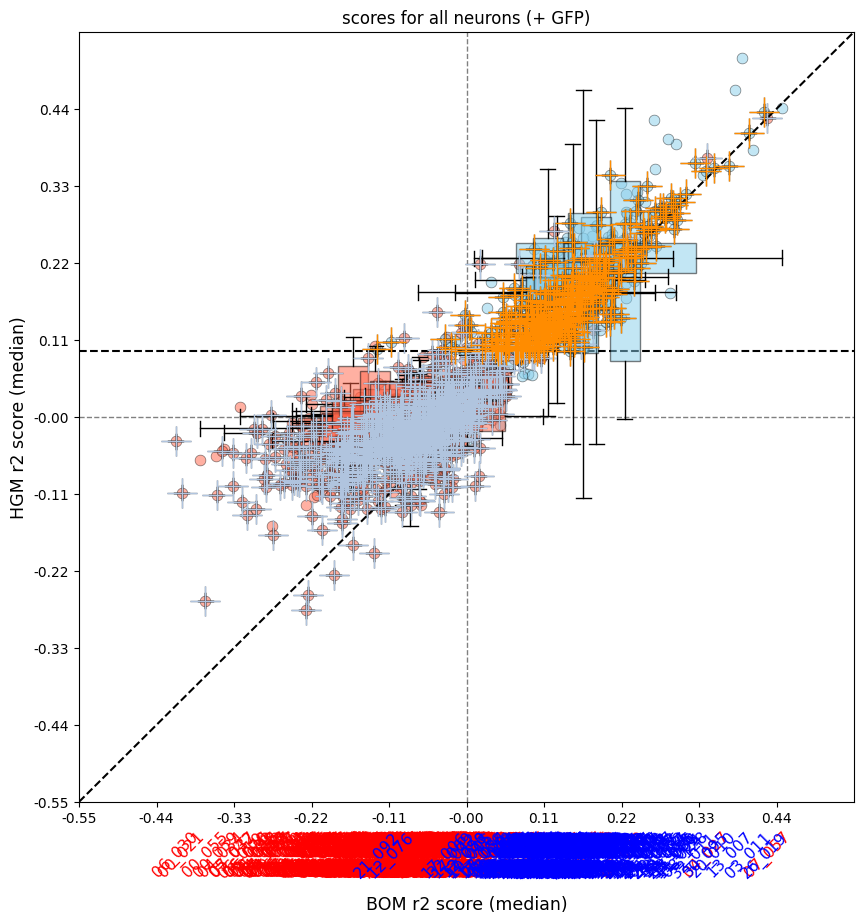

In [49]:
if gcamp and gfp:
	plot_utils.plot_performance_plot(neuron_scores_gcamp, neuron_scores_gfp,
									 title='scores for all neurons (+ GFP)', limits=(-0.55, 0.55, -0.55, 0.55))

In [50]:
if gcamp and gfp:
	high_score_hgm_gfp = np.quantile(np.concatenate([pair[1] for pair in neuron_scores_gfp.values()]), 0.95)

	selection_n_hgmssig = list()
	for key in neuron_scores_gcamp.keys():
		scores_bom, scores_hgm = neuron_scores_gcamp[key]
		if len(scores_hgm.shape) == 0:
			scores_bom = scores_bom.reshape(1, 1)
			scores_hgm = scores_hgm.reshape(1, 1)
		y = np.median(scores_hgm)
		if y > high_score_hgm_gfp:
			selection_n_hgmssig.append(key)

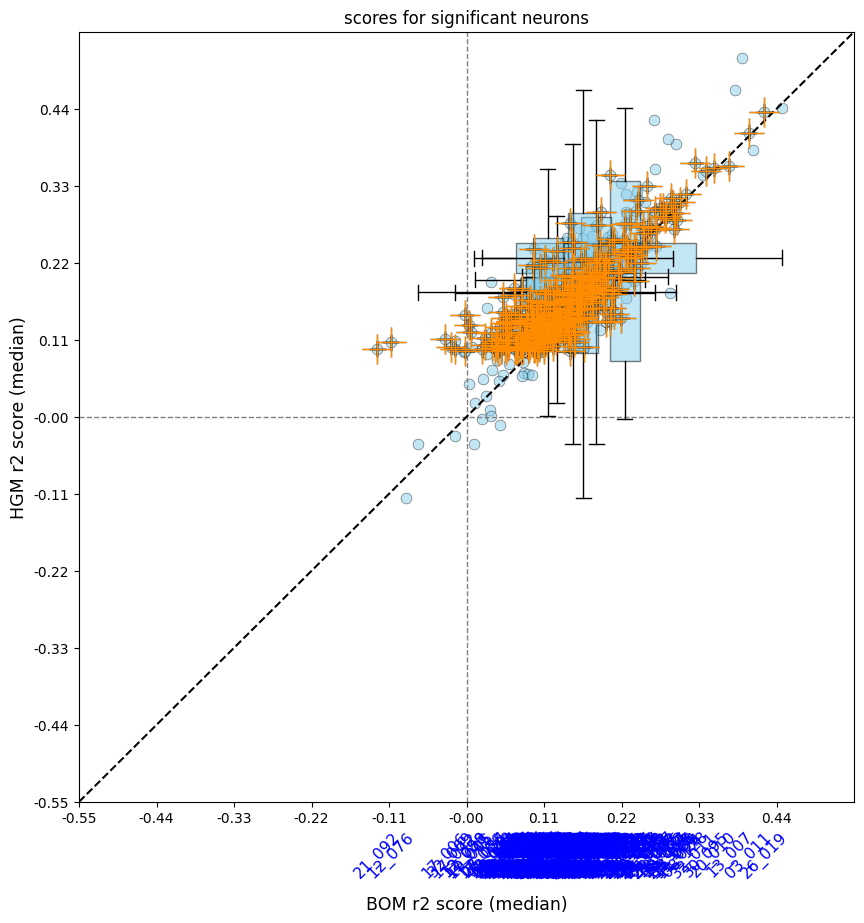

In [51]:
if gcamp and gfp:
	plot_utils.plot_performance_plot({key: neuron_scores_gcamp[key] for key in selection_n_hgmssig if key in neuron_scores_gcamp.keys()}, None,
									 title='scores for significant neurons', limits=(-0.55, 0.55, -0.55, 0.55))

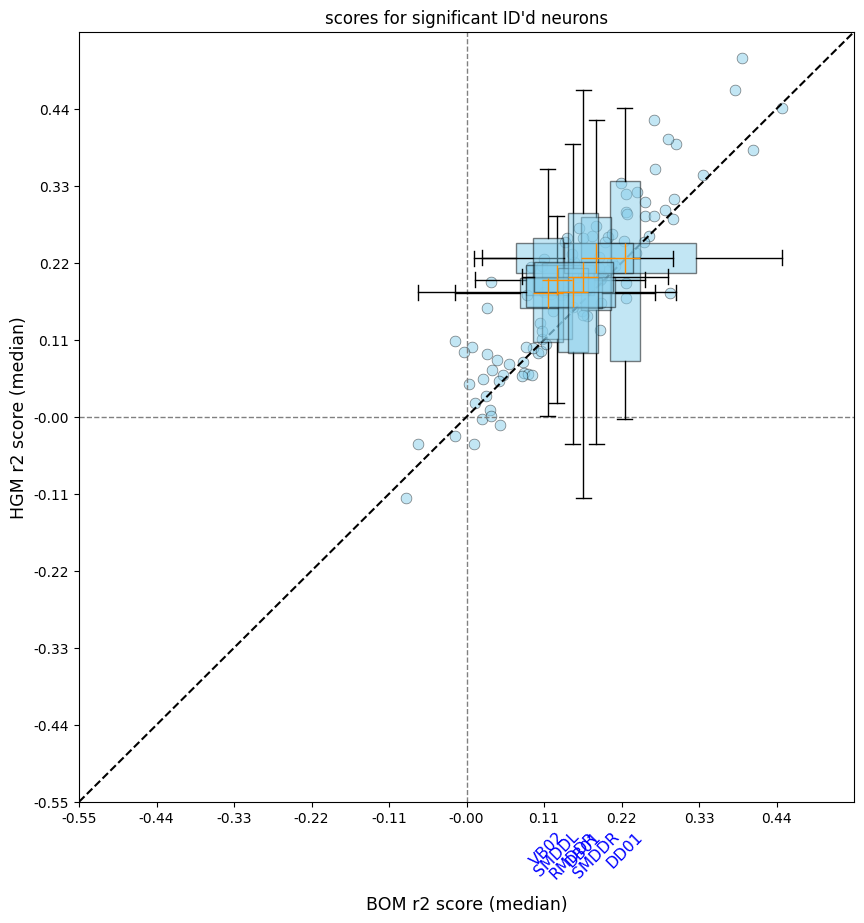

In [52]:
if gcamp and gfp:
	plot_utils.plot_performance_plot({key: neuron_scores_gcamp[key] for key in selection_n_hgmssig if key in neuron_scores_gcamp.keys() and not key[0].isdigit()}, None,
									 title='scores for significant ID\'d neurons', limits=(-0.55, 0.55, -0.55, 0.55))

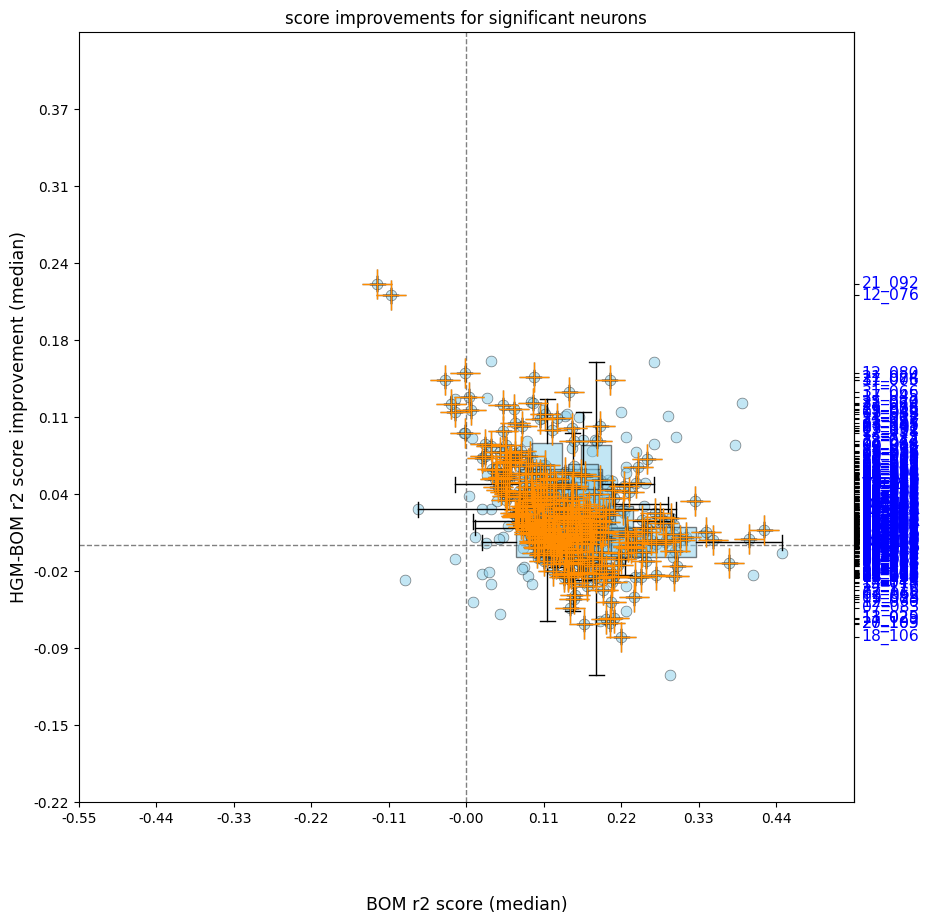

In [53]:
if gcamp and gfp:
	plot_utils.plot_improvement_plot_y({key: neuron_scores_gcamp[key] for key in selection_n_hgmssig if key in neuron_scores_gcamp.keys()}, None,
									   title='score improvements for significant neurons', limits=(-0.55, 0.55, -0.22, 0.44))

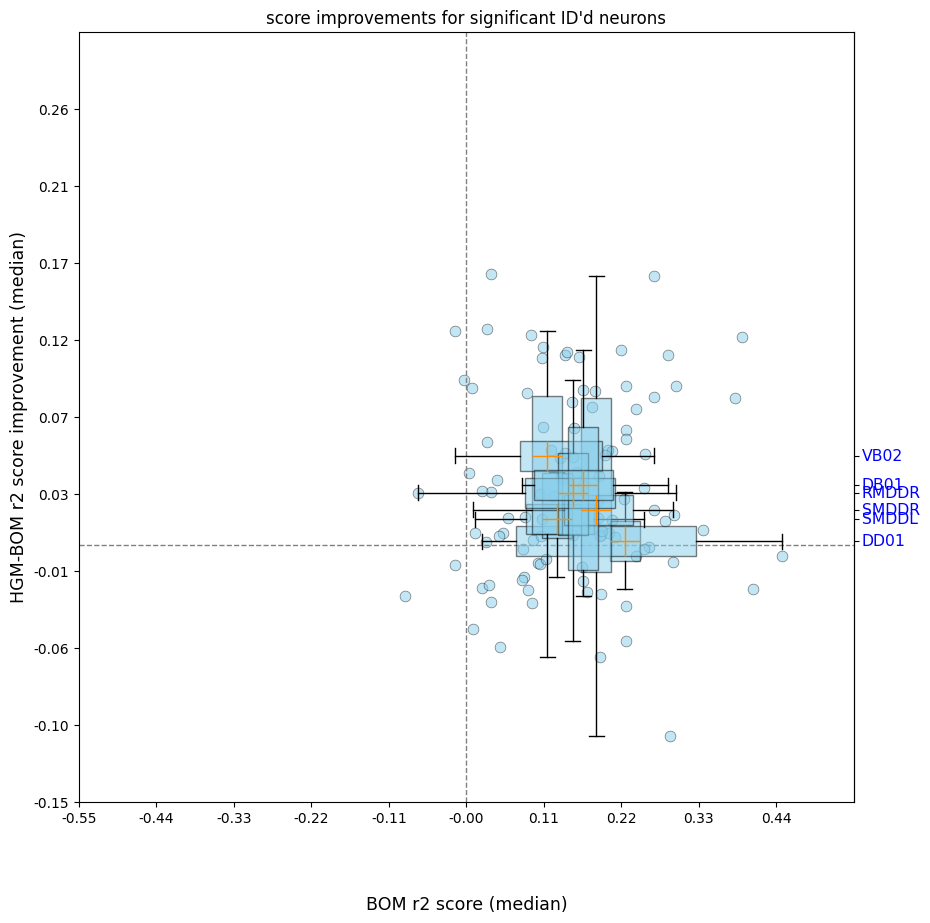

In [54]:
if gcamp and gfp:
	plot_utils.plot_improvement_plot_y({key: neuron_scores_gcamp[key] for key in selection_n_hgmssig if key in neuron_scores_gcamp.keys() and not key[0].isdigit()}, None,
									   title='score improvements for significant ID\'d neurons', limits=(-0.55, 0.55, -0.15, 0.30))

In [55]:
print('\n'.join([f'NEURON: {key},\tIMPR: {np.median(val[1] - val[0]):.4f}' for key, val in reversed(sorted(neuron_scores_gcamp.items(), key=lambda x: np.median(x[1][1] - x[1][0]))) if key in selection_n_hgmssig and not key[0].isdigit()]))

NEURON: VB02,	IMPR: 0.0523
NEURON: DB01,	IMPR: 0.0351
NEURON: RMDDR,	IMPR: 0.0308
NEURON: SMDDR,	IMPR: 0.0206
NEURON: SMDDL,	IMPR: 0.0151
NEURON: DD01,	IMPR: 0.0024


In [56]:
# raise Exception

### IDd neurons

In [57]:
# n_best = 20

In [58]:
# if gcamp and gfp:
# 	selection_n_hgmssig_ids = [label for label in selection_n_hgmssig if not label[0].isdigit()]

In [59]:
# if gcamp and gfp:
# 	selection_n_hgmssig_ids = [label for label in selection_n_hgmssig_ids if label in traces_gcamp[file_ids_gcamp.index(plot_id_gcamp)].columns]

In [60]:
# for label in selection_n_hgmssig_ids[:n_best]:
# 	labels = [label]
#
# 	splits = 5
# 	plot_utils.plot_traces_x_splits(
# 		f'{filenames_gcamp[file_ids_gcamp.index(plot_id_gcamp)]} gcamp hgm & bom definitions manifold',
# 		discrete_states_gcamp[file_ids_gcamp.index(plot_id_gcamp)][['REV']],
# 		traces_gcamp_cca_rec[file_ids_gcamp.index(plot_id_gcamp)][labels],
# 		[hgms_rec_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][labels] for i in range(splits)],
# 		[boms_rec_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][labels] for i in range(splits)],
# 		plot_first=True, plots_per_row=1, ylimits=None,
# 		save_name=None)  #f'traces-no-id/{label}-manifolds'
#
# 	splits = 5
# 	plot_utils.plot_traces_x_splits(
# 		f'{filenames_gcamp[file_ids_gcamp.index(plot_id_gcamp)]} gcamp hgm & bom definitions residuals',
# 		discrete_states_gcamp[file_ids_gcamp.index(plot_id_gcamp)][['REV']],
# 		traces_gcamp_cca_res[file_ids_gcamp.index(plot_id_gcamp)][labels],
# 		[hgms_res_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][labels] for i in range(splits)],
# 		[boms_res_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][labels] for i in range(splits)],
# 		plot_first=True, plots_per_row=1, ylimits=None,
# 		save_name=None)  #f'traces-no-id/{label}-residuals'
#
# 	for i in range(5):
# 		plot_utils.plot_traces_comparisons(
# 			f'{filenames_gcamp[file_ids_gcamp.index(plot_id_gcamp)]} split {i} gcamp hgm & bom predictions residuals',
# 			discrete_states_gcamp[file_ids_gcamp.index(plot_id_gcamp)][['REV']],
# 			traces_gcamp_cca_res[file_ids_gcamp.index(plot_id_gcamp)][labels],
# 			[hgms_res_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][labels],
# 			 hgms_pres_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][labels]],
# 			[boms_res_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][labels],
# 			 boms_pres_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][labels]],
# 			plot_first=False, plots_per_row=1, ylimits=None,
# 			save_name=None)  #f'traces-no-id/{label}-prediction-s{i}'

In [61]:
# raise Exception

### non IDd neurons

In [62]:
# if gcamp and gfp:
# 	selection_n_hgmssig_nonids = [label for label in selection_n_hgmssig if label[0].isdigit()]

In [63]:
# if gcamp and gfp:
# 	selection_n_hgmssig_nonids = [label for label in selection_n_hgmssig_nonids if label in traces_gcamp[file_ids_gcamp.index(plot_id_gcamp)].columns]

In [64]:
# for label in selection_n_hgmssig_nonids[:n_best]:
# 	labels = [label]
# 	plot_id_gcamp = int(label.split('_')[0])
#
# 	splits = 5
# 	plot_utils.plot_traces_x_splits(
# 		f'{filenames_gcamp[file_ids_gcamp.index(plot_id_gcamp)]} gcamp hgm & bom definitions manifold',
# 		discrete_states_gcamp[file_ids_gcamp.index(plot_id_gcamp)][['REV']],
# 		traces_gcamp[file_ids_gcamp.index(plot_id_gcamp)][labels],
# 		[hgms_rec_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][labels] for i in range(splits)],
# 		[boms_rec_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][labels] for i in range(splits)],
# 		plot_first=True, plots_per_row=1, ylimits=None,
# 		save_name=None)  #f'traces-no-id/{label}-manifolds'
#
# 	splits = 5
# 	plot_utils.plot_traces_x_splits(
# 		f'{filenames_gcamp[file_ids_gcamp.index(plot_id_gcamp)]} gcamp hgm & bom definitions residuals',
# 		discrete_states_gcamp[file_ids_gcamp.index(plot_id_gcamp)][['REV']],
# 		traces_gcamp[file_ids_gcamp.index(plot_id_gcamp)][labels],
# 		[hgms_res_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][labels] for i in range(splits)],
# 		[boms_res_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][labels] for i in range(splits)],
# 		plot_first=True, plots_per_row=1, ylimits=None,
# 		save_name=None)  #f'traces-no-id/{label}-residuals'
#
# 	for i in range(5):
# 		plot_utils.plot_traces_comparisons(
# 			f'{filenames_gcamp[file_ids_gcamp.index(plot_id_gcamp)]} split {i} gcamp hgm & bom predictions residuals',
# 			discrete_states_gcamp[file_ids_gcamp.index(plot_id_gcamp)][['REV']],
# 			traces_gcamp[file_ids_gcamp.index(plot_id_gcamp)][labels],
# 			[hgms_res_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][labels],
# 			 hgms_pres_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][labels]],
# 			[boms_res_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][labels],
# 			 boms_pres_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][labels]],
# 			plot_first=False, plots_per_row=1, ylimits=None,
# 			save_name=None)  #f'traces-no-id/{label}-prediction-s{i}'

## Itamar

In [65]:
# raise Exception

In [66]:
# idd = False
#
# selection_n_traces_chosen = sorted([label for label in neuron_scores_gcamp.keys() if label[0].isdigit() is not idd])
#
# high_score_hgm_gfp = np.quantile(np.concatenate([pair[1] for pair in neuron_scores_gfp.values()]), 0.95)
# high_score_bom_gfp = np.quantile(np.concatenate([pair[1] for pair in neuron_scores_gfp.values()]), 0.95)
#
# neuron_scores_signficance = dict()
# for key in selection_n_traces_chosen:
# 	scores_bom, scores_hgm = neuron_scores_gcamp[key]
# 	if len(scores_hgm.shape) == 0:
# 		scores_bom = scores_bom.reshape(1, 1)
# 		scores_hgm = scores_hgm.reshape(1, 1)
#
# 	neuron_scores_signficance[key] = (np.median(scores_bom) > high_score_hgm_gfp, np.median(scores_hgm) > high_score_hgm_gfp)
#
# neuron_scores_median_impr = {key: np.median(neuron_scores_gcamp[key][1] - neuron_scores_gcamp[key][0]) for key in selection_n_traces_chosen}

In [67]:
# data = [[key,
# 		 neuron_scores_gcamp[key][0][0][0],
# 		 neuron_scores_gcamp[key][1][0][0],
# 		 neuron_scores_signficance[key][0],
# 		 neuron_scores_signficance[key][1],
# 		 neuron_scores_median_impr[key]] for key in selection_n_traces_chosen]
# if not idd:
# 	prepend = [filenames_gcamp[file_ids_gcamp.index(int(key.split('_')[0]))] for key in selection_n_traces_chosen]
# 	for e, p in zip(data, prepend): e.insert(0, p)
#
# df = pd.DataFrame(data, columns=(['Worm'] if not idd else []) + ['Neuron', 'BOM_score', 'HGM_score', 'BOM_score_significant', 'HGM_score_significant', 'HGM-BOM_score_improvement'])
# df.to_csv(f'./out/data/{'non' if not idd else ''}id_neurons.csv', index=False)

# playground

In [68]:
gating_gcamp = np.array(jax.nn.sigmoid(hgms_params_gcamp[file_ids_gcamp.index(plot_id_gcamp)][2]['model']['W2'] * 1))

In [69]:
gating_art = np.array(jax.nn.sigmoid(hgms_params_art[file_ids_gcamp.index(plot_id_gcamp)][2]['model']['W2'] * 1))

In [95]:
def rowwisecorrel(A, B):
	num = np.sum(A.values * B.values, axis=1)
	den = np.sqrt(np.sum(A.values**2, axis=1) * np.sum(B.values**2, axis=1))
	# return num / den
	return num

# print(file_ids_gcamp.index(plot_id_gcamp))

selection_n_hgmssig_ids = [label for label in selection_n_hgmssig if label in traces_gcamp[file_ids_gcamp.index(plot_id_gcamp)].columns if not label[0].isdigit()]


DS_19 = discrete_states_gcamp[file_ids_gcamp.index(plot_id_gcamp)]

BOM_DEFINED_19 = boms_res_art_full[file_ids_gcamp.index(plot_id_gcamp)][1][selection_n_hgmssig_ids]
BOM_PREDICTED_19 = boms_pres_art_full[file_ids_gcamp.index(plot_id_gcamp)][1][selection_n_hgmssig_ids]

BOM_DEFINED_19_fwd = BOM_DEFINED_19.loc[DS_19['REV'] == 0][selection_n_hgmssig_ids]
BOM_PREDICTED_19_fwd = BOM_PREDICTED_19.loc[DS_19['REV'] == 0][selection_n_hgmssig_ids]

BOM_DEFINED_19_rev = BOM_DEFINED_19.loc[DS_19['REV'] == 1]
BOM_PREDICTED_19_rev = BOM_PREDICTED_19.loc[DS_19['REV'] == 1]



HGM_DEFINED_19 = hgms_res_art_full[file_ids_gcamp.index(plot_id_gcamp)][1][selection_n_hgmssig_ids]
HGM_PREDICTED_19 = hgms_pres_art_full[file_ids_gcamp.index(plot_id_gcamp)][1][selection_n_hgmssig_ids]

HGM_DEFINED_19_fwd = HGM_DEFINED_19.loc[DS_19['REV'] == 0][selection_n_hgmssig_ids]
HGM_PREDICTED_19_fwd = HGM_PREDICTED_19.loc[DS_19['REV'] == 0][selection_n_hgmssig_ids]

HGM_DEFINED_19_rev = HGM_DEFINED_19.loc[DS_19['REV'] == 1]
HGM_PREDICTED_19_rev = HGM_PREDICTED_19.loc[DS_19['REV'] == 1]



# resets row indices
BOM_DEFINED_19 = pd.DataFrame(data=BOM_DEFINED_19.values, columns=BOM_DEFINED_19.columns)
BOM_DEFINED_19_fwd = pd.DataFrame(data=BOM_DEFINED_19_fwd.values, columns=BOM_DEFINED_19_fwd.columns)
BOM_DEFINED_19_rev = pd.DataFrame(data=BOM_DEFINED_19_rev.values, columns=BOM_DEFINED_19_rev.columns)

HGM_DEFINED_19 = pd.DataFrame(data=HGM_DEFINED_19.values, columns=HGM_DEFINED_19.columns)
HGM_DEFINED_19_fwd = pd.DataFrame(data=HGM_DEFINED_19_fwd.values, columns=HGM_DEFINED_19_fwd.columns)
HGM_DEFINED_19_rev = pd.DataFrame(data=HGM_DEFINED_19_rev.values, columns=HGM_DEFINED_19_rev.columns)


print('BOM FWD correl', np.mean(rowwisecorrel(BOM_DEFINED_19_fwd, BOM_PREDICTED_19_fwd)))
print('BOM REV correl', np.mean(rowwisecorrel(BOM_DEFINED_19_rev, BOM_PREDICTED_19_rev)))

print('HGM FWD correl', np.mean(rowwisecorrel(HGM_DEFINED_19_fwd, HGM_PREDICTED_19_fwd)))
print('HGM REV correl', np.mean(rowwisecorrel(HGM_DEFINED_19_rev, HGM_PREDICTED_19_rev)))

BOM FWD correl 0.10260757
BOM REV correl 0.02485983
HGM FWD correl 0.16816103
HGM REV correl 0.000104894316


In [96]:
BOM_DEFPRED_DIFF_fwd = pd.DataFrame(BOM_DEFINED_19_fwd.values - BOM_PREDICTED_19_fwd.values, columns=BOM_DEFINED_19_fwd.columns).abs()
HGM_DEFPRED_DIFF_fwd = pd.DataFrame(HGM_DEFINED_19_fwd.values - HGM_PREDICTED_19_fwd.values, columns=BOM_DEFINED_19_fwd.columns).abs()

BOM_DEFPRED_DIFF_rev = pd.DataFrame(BOM_DEFINED_19_rev.values - BOM_PREDICTED_19_rev.values, columns=BOM_DEFINED_19_fwd.columns).abs()
HGM_DEFPRED_DIFF_rev = pd.DataFrame(HGM_DEFINED_19_rev.values - HGM_PREDICTED_19_rev.values, columns=BOM_DEFINED_19_fwd.columns).abs()

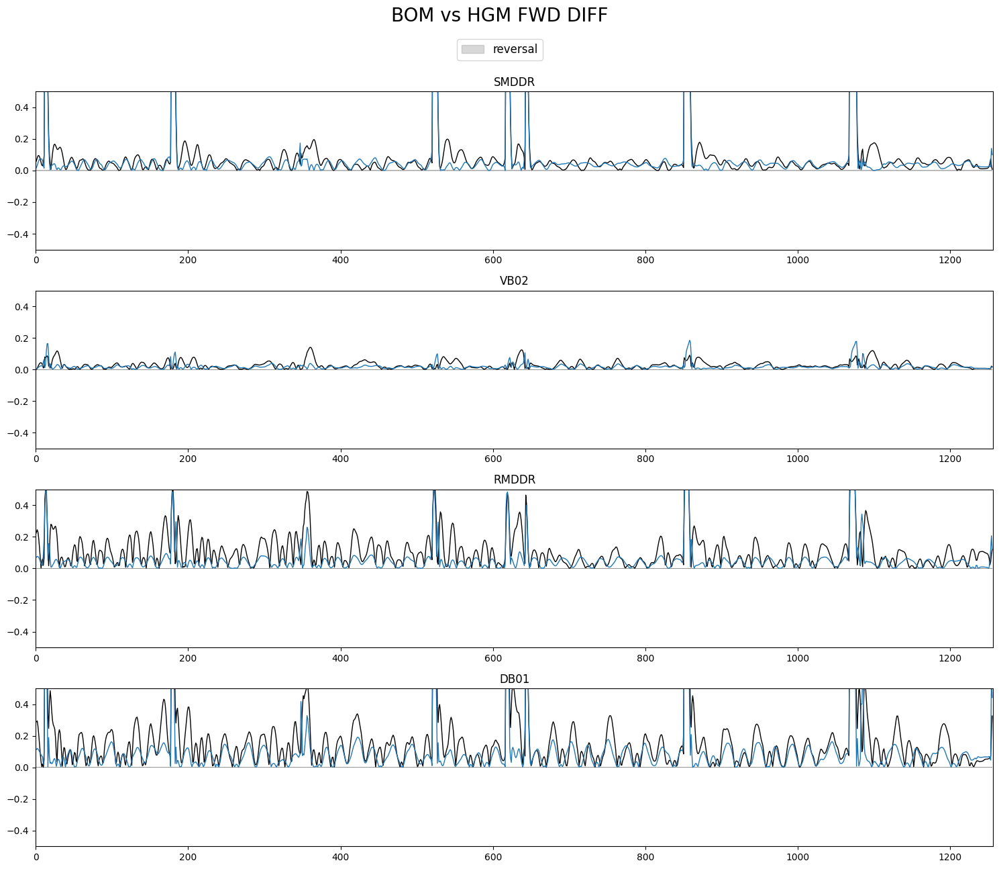

0.047857977


In [90]:
plot_utils.plot_traces('BOM vs HGM FWD DIFF',
					   pd.DataFrame(data=np.array([0 for _ in range(BOM_DEFPRED_DIFF_fwd.shape[0])])),
					   [BOM_DEFPRED_DIFF_fwd,
						HGM_DEFPRED_DIFF_fwd],
					   plots_per_row=1, ylimits=(-0.5, 0.5))

print(np.abs(BOM_DEFPRED_DIFF_fwd.values - HGM_DEFPRED_DIFF_fwd.values).mean())

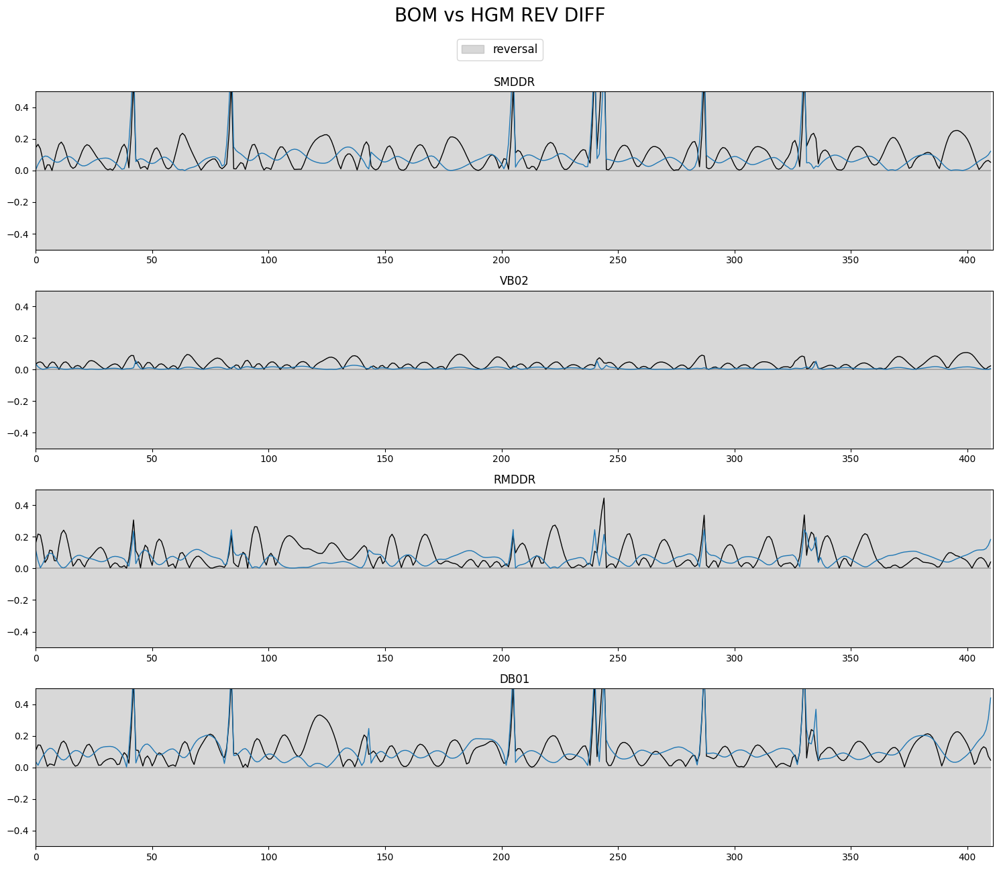

0.06269643


In [94]:
plot_utils.plot_traces('BOM vs HGM REV DIFF',
					   pd.DataFrame(data=np.array([1 for _ in range(BOM_DEFPRED_DIFF_rev.shape[0] - 1)] + [0])),
					   [BOM_DEFPRED_DIFF_rev,
						HGM_DEFPRED_DIFF_rev],
					   plots_per_row=1, ylimits=(-0.5, 0.5))

print(np.abs(BOM_DEFPRED_DIFF_rev.values - HGM_DEFPRED_DIFF_rev.values).mean())